# Лабораторная работа №1
## Численные методы алгебры

**Цель:** реализовать прямые и итерационные методы решения СЛАУ, методы решения нелинейных уравнений и систем; исследовать точность, обусловленность и сходимость.


### Правила выполнения
- Сделайте собственную копию блокнота. Заполняйте ячейки с `TODO`, добавляйте эксперименты и выводы непосредственно в него.
- XML-модели, визуализация и регулятор предоставлены готовыми. Их переписывать не требуется.
- В собственных решателях запрещены `np.linalg.solve`, `inv`, `lu`, `cholesky` и аналогичные готовые решатели/разложения. Они разрешены только для эталонных проверок. `norm`, матричные операции и вычисление числа обусловленности разрешены.
- Использование агентов разрешено. На защите необходимо объяснить код, предсказать результат изменения параметров и провести эксперимент.
- Задания обозначены **А1–А5, Б1–Б3**.

## Подготовка
При первой установке выполните следующую ячейку. Затем перезапустите сеанс через меню «Среда выполнения → Перезапустить сеанс» и продолжите с импортов. Если MuJoCo уже импортировался с другим OpenGL-бэкендом, перезапуск обязателен. GPU не требуется.


In [7]:
!apt-get -qq update
!apt-get -qq install -y libosmesa6
%pip -q install mujoco==3.3.7 mediapy


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [8]:
import os

# Обязательно до импорта mujoco или OpenGL.
os.environ["MUJOCO_GL"] = "osmesa"
os.environ["PYOPENGL_PLATFORM"] = "osmesa"

import ctypes
import ctypes.util

library_path = ctypes.util.find_library("OSMesa")
print("Библиотека OSMesa:", library_path)

if library_path is None:
    raise RuntimeError("OSMesa не найдена. Повтори установку libosmesa6.")

ctypes.CDLL(library_path)

import numpy as np
import matplotlib.pyplot as plt
import mujoco
import mediapy as media
from time import perf_counter

print("MuJoCo:", mujoco.__version__)


Библиотека OSMesa: libOSMesa.so.8
MuJoCo: 3.3.7


# А. СЛАУ и равновесие упругой решётки
## А1. Реализация прямых методов
Реализуйте метод Гаусса с частичным выбором главного элемента, [LU с перестановками строк](https://ru.wikipedia.org/wiki/LUP-разложение) ($PA=LU$), метод Холецкого и треугольные решатели.

Функции не должны изменять исходные массивы. Предусмотрите диагностику вырожденных систем и неположительно определённых матриц.

`lu_factor` возвращает `(P, L, U)`; `cholesky_factor` — нижнетреугольную матрицу `L`.


In [9]:
def forward_substitution(L, b):
    n = L.shape[0]
    x = np.zeros(n)
    for i in range(n):
        if np.abs(L[i, i]) < 1e-14:
            raise ValueError("Нижнетреугольная матрица вырождена")
        x[i] = (b[i] - np.dot(L[i, :i], x[:i])) / L[i, i]
    return x

def backward_substitution(U, b):
    n = U.shape[0]
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        if np.abs(U[i, i]) < 1e-14:
            raise ValueError("Верхнетреугольная матрица вырождена")
        x[i] = (b[i] - np.dot(U[i, i + 1:], x[i + 1:])) / U[i, i]
    return x

def gauss(A, b):
    A_work = np.array(A, dtype=float)
    b_work = np.array(b, dtype=float)
    n = len(b)

    for i in range(n):
        pivot = np.argmax(np.abs(A_work[i:, i])) + i
        if np.abs(A_work[pivot, i]) < 1e-14:
            raise ValueError("Матрица вырождена")

        if pivot != i:
            A_work[[i, pivot]] = A_work[[pivot, i]]
            b_work[[i, pivot]] = b_work[[pivot, i]]

        for j in range(i + 1, n):
            factor = A_work[j, i] / A_work[i, i]
            A_work[j, i:] -= factor * A_work[i, i:]
            b_work[j] -= factor * b_work[i]

    return backward_substitution(A_work, b_work)

def lu_factor(A):
    n = A.shape[0]
    U = np.array(A, dtype=float)
    L = np.eye(n)
    P = np.eye(n)

    for i in range(n):
        pivot = np.argmax(np.abs(U[i:, i])) + i
        if np.abs(U[pivot, i]) < 1e-14:
            raise ValueError("Матрица вырождена")

        if pivot != i:
            U[[i, pivot]] = U[[pivot, i]]
            P[[i, pivot]] = P[[pivot, i]]
            if i > 0:
                L[[i, pivot], :i] = L[[pivot, i], :i]

        for j in range(i + 1, n):
            factor = U[j, i] / U[i, i]
            L[j, i] = factor
            U[j, i:] -= factor * U[i, i:]

    return P, L, U

def lu_solve(factors, b):
    P, L, U = factors
    return backward_substitution(U, forward_substitution(L, P @ b))

def cholesky_factor(A):
    # Проверка на симметрию
    if not np.allclose(A, A.T, atol=1e-9):
        raise ValueError("Матрица не симметрична")

    n = A.shape[0]
    L = np.zeros_like(A, dtype=float)

    for i in range(n):
        for j in range(i + 1):
            sum_k = np.dot(L[i, :j], L[j, :j])
            if i == j:
                val = A[i, i] - sum_k
                if val <= 0:
                    raise ValueError("Матрица не является положительно определенной")
                L[i, i] = np.sqrt(val)
            else:
                L[i, j] = (A[i, j] - sum_k) / L[j, j]

    return L

def cholesky_solve(A, b):
    L = cholesky_factor(A)
    return backward_substitution(L.T, forward_substitution(L, b))

### Контрольные проверки А1
Ячейка проверяет решение, восстановление разложений и сохранение исходных данных. Добавьте собственные проверки вырожденной системы и отказа Холецкого для неподходящей матрицы. Прохождение этих проверок не заменяет эксперименты.


In [10]:
rng = np.random.default_rng(42)
for size in (10, 50):
    B = rng.normal(size=(size, size))
    A = B + (size + 1)*np.eye(size)
    x_exact = rng.normal(size=size)
    b = A @ x_exact
    A_before, b_before = A.copy(), b.copy()
    P, L, U = lu_factor(A)
    np.testing.assert_allclose(P @ A, L @ U, atol=1e-9)
    for x in (gauss(A, b), lu_solve((P, L, U), b)):
        np.testing.assert_allclose(x, x_exact, rtol=1e-8, atol=1e-9)
    np.testing.assert_array_equal(A, A_before)
    np.testing.assert_array_equal(b, b_before)
    S = B.T @ B + np.eye(size)
    C = cholesky_factor(S)
    np.testing.assert_allclose(C @ C.T, S, atol=1e-9)
    np.testing.assert_allclose(cholesky_solve(S, S @ x_exact), x_exact,
                               rtol=1e-8, atol=1e-9)
A_pivot = np.array([[0., 2.], [1., 3.]])
b_pivot = A_pivot @ np.array([1., -2.])
np.testing.assert_allclose(gauss(A_pivot, b_pivot), [1., -2.])
np.testing.assert_allclose(lu_solve(lu_factor(A_pivot), b_pivot), [1., -2.])
print("Базовые проверки А1 пройдены.")


Базовые проверки А1 пройдены.


## 1. Упругая решётка: математическая модель

Рассмотрим решётку площадок, каждая из которых может перемещаться только вертикально. Соседние площадки соединены упругими связями. Каждая площадка также имеет пружинную опору относительно неподвижного основания.

Положительное перемещение $u_i$ направлено вниз.

Обозначения:
- $k_0$ — жёсткость опоры;
- $k_c$ — жёсткость связи соседей;
- $f_i$ — внешняя сила, направленная вниз;
- $N(i)$ — множество соседей площадки $i$.

Условие равновесия площадки:

$$
k_0u_i+\sum_{j\in N(i)}k_c(u_i-u_j)=f_i.
$$

Система уравнений всех площадок записывается в виде

$$
Ku=f.
$$

Элементы матрицы:

$$
K_{ii}=k_0+|N(i)|k_c,
$$

$$
K_{ij}=-k_c
$$

для соседних площадок; остальные внедиагональные элементы равны нулю.

При $k_0>0$ и $k_c>0$ матрица симметрична и положительно определена:

$$
u^\top Ku
=
k_0\sum_i u_i^2+
k_c\sum_{(i,j)\in E}(u_i-u_j)^2>0
$$

для любого ненулевого $u$. Каждая связь в множестве $E$ учитывается один раз.

При $k_0=0$ одинаковое перемещение всех площадок не деформирует связи. Матрица становится вырожденной.

Количество неизвестных: 25
Число обусловленности: 20.296181273332795
Минимальное собственное значение: 15.000000000000007


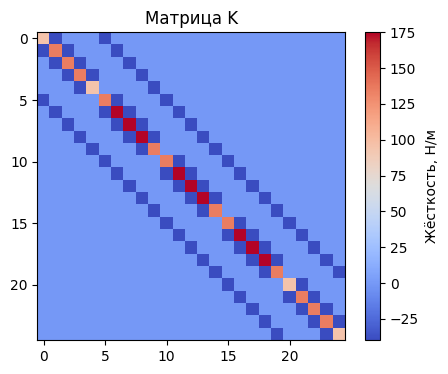

In [11]:
SIDE = 5                  # SIDE × SIDE площадок
SPACING = 0.22            # расстояние между центрами, м
HEIGHT = 0.65             # исходная высота, м
MASS = 0.15               # масса каждой площадки, кг

K_SUPPORT = 15.0          # жёсткость опоры каждого узла, Н/м
K_COUPLING = 40.0         # жёсткость связи соседей, Н/м
DAMPING = 0.6             # демпфирование каждого сустава, Н·с/м

n = SIDE**2

def index(row, col):
    return row * SIDE + col

xy = np.array([
    [(col - (SIDE - 1)/2) * SPACING,
     (row - (SIDE - 1)/2) * SPACING]
    for row in range(SIDE)
    for col in range(SIDE)
])

# Каждую связь включаем один раз.
edges = []
for row in range(SIDE):
    for col in range(SIDE):
        i = index(row, col)
        if col + 1 < SIDE:
            edges.append((i, index(row, col + 1)))
        if row + 1 < SIDE:
            edges.append((i, index(row + 1, col)))

# Опоры дают диагональную часть.
K = K_SUPPORT * np.eye(n)

# Связь i–j даёт энергию kc/2 * (ui - uj)^2.
for i, j in edges:
    K[i, i] += K_COUPLING
    K[j, j] += K_COUPLING
    K[i, j] -= K_COUPLING
    K[j, i] -= K_COUPLING

# Постоянная сила вниз на центральной площадке.
f = np.zeros(n)
loaded_node = index(SIDE // 2, SIDE // 2)
f[loaded_node] = 8.0

print("Количество неизвестных:", n)
print("Число обусловленности:", np.linalg.cond(K))
print("Минимальное собственное значение:", np.linalg.eigvalsh(K)[0])

plt.figure(figsize=(5, 4))
plt.imshow(K, cmap="coolwarm")
plt.colorbar(label="Жёсткость, Н/м")
plt.title("Матрица K")
plt.show()


## А2. Итерационные методы
Реализуйте Якоби и Гаусса–Зейделя. В Якоби все компоненты следующего приближения вычисляются по прежнему вектору; в Зейделе используются уже обновлённые компоненты.

Критерий останова:
$$\|Ax^{(k)}-b\|_2\leq \text{atol}+\text{rtol}\|b\|_2.$$

Функция возвращает решение и массив норм невязок, включая начальную. Число шагов равно `len(residuals)-1`. При исчерпании лимита или нечисловых значениях сообщайте об ошибке. `x0=None` означает нулевой старт.


In [12]:
def iterative_solve(A, b, method="jacobi", x0=None,
                    rtol=1e-9, atol=1e-12, max_iter=20000):

    N = len(b)

    # начально приближение
    if x0 is None:
      x = np.zeros_like(b, dtype=float)
    else:
      x = x0.copy()

    residuals = [np.linalg.norm(A @ x -b)]
    threshold = atol + rtol * np.linalg.norm(b)

    # начальное приближение уже идеальное
    if residuals[0] <= threshold:
      return x, np.array(residuals)

    if method == "jacobi":
      D = np.diag(A)
      if np.any(D == 0):
        raise ValueError("на диагонали есть нули, деление невозможно")

    for k in range(max_iter):

      if method == "jacobi":
        x_new = (b - A @ x + D * x) / D
        x = x_new

      elif method == "seidel":
        for i in range(N):
          sigma = np.dot(A[i, :i], x[:i]) + np.dot(A[i, i+1:], x[i+1:])
          if A[i, i] == 0:
            raise ValueError("на диагонали есть нули, деление невозможно")
          x[i] = (b[i] - sigma) / A[i, i]

      else:
            raise ValueError(f"Неизвестный метод: {method}. Ожидается 'jacobi' или 'seidel'.")

      # новая невязка
      res = np.linalg.norm(A @ x - b)
      residuals.append(res)

      # ппроверка на расходимость
      if not np.isfinite(res):
          raise RuntimeError("Метод разошелся, получены нечисловые значения (NaN или Inf). "
                            "Возможно, матрица вырождена (например, k0 = 0).")

      # проверка критерия остановки
      if res <= threshold:
          return x, np.array(residuals)

    raise RuntimeError(f"Метод не сошелся за максимальное число итераций ({max_iter}). "
                       f"Текущая невязка: {residuals[-1]:.2e}")



### Сравнение на одной нагрузке
Ниже используется библиотечное эталонное решение. Время одного короткого запуска не позволяет сделать надёжный вывод о скорости: для экспериментов используйте повторы и медиану времени.


Гаусс     : невязка = 2.90e-15, время = 1.36 мс
LU        : невязка = 3.28e-15, время = 1.77 мс
Холецкий  : невязка = 2.05e-15, время = 1.19 мс
Гаусс     : относительное расхождение = 2.68e-16
LU        : относительное расхождение = 2.92e-16
Холецкий  : относительное расхождение = 5.14e-16
Якоби     : относительное расхождение = 2.74e-09
Зейдель   : относительное расхождение = 3.38e-09


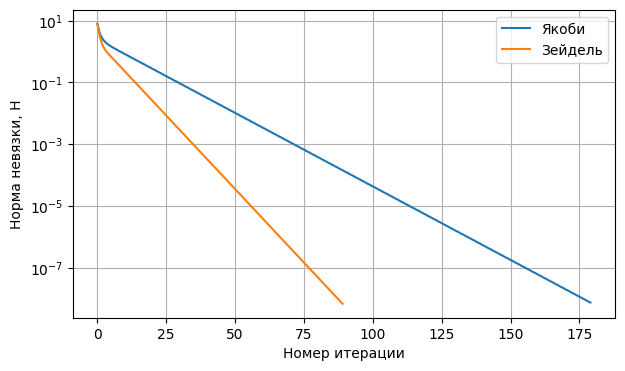

Итераций Якоби: 179
Итераций Зейделя: 89
Максимальный прогиб: 73.9 мм


In [13]:
u_reference = np.linalg.solve(K, f)

results = {}

for name, solver in [
    ("Гаусс", gauss),
    ("LU", lambda A, b: lu_solve(lu_factor(A), b)),
    ("Холецкий", cholesky_solve),
]:
    start = perf_counter()
    u = solver(K, f)
    elapsed = perf_counter() - start
    results[name] = u

    print(
        f"{name:10s}: "
        f"невязка = {np.linalg.norm(K @ u - f):.2e}, "
        f"время = {elapsed*1000:.2f} мс"
    )

u_jacobi, r_jacobi = iterative_solve(K, f, "jacobi")
u_seidel, r_seidel = iterative_solve(K, f, "seidel")

results["Якоби"] = u_jacobi
results["Зейдель"] = u_seidel

for name, u in results.items():
    relative_error = (
        np.linalg.norm(u - u_reference)
        / np.linalg.norm(u_reference)
    )
    print(f"{name:10s}: относительное расхождение = {relative_error:.2e}")

plt.figure(figsize=(7, 4))
plt.semilogy(r_jacobi, label="Якоби")
plt.semilogy(r_seidel, label="Зейдель")
plt.xlabel("Номер итерации")
plt.ylabel("Норма невязки, Н")
plt.grid()
plt.legend()
plt.show()

print("Итераций Якоби:", len(r_jacobi) - 1)
print("Итераций Зейделя:", len(r_seidel) - 1)
print(f"Максимальный прогиб: {u_reference.max()*1000:.1f} мм")

# Это решение будет показано в MuJoCo красными метками.
u_static = results["Гаусс"].copy()


## А3. Проверка физической симуляцией
В MuJoCo каждая площадка имеет вертикальный сустав; `fixed tendon` задаёт пружину с координатой $u_i-u_j$. Гравитация и контакты отключены, силы задаются явно.

Динамика происходящего описывается уравнением: $M\ddot u+C\dot u+Ku=f$, где матрица $M$ скрывает инерционные свойства системы, а $C$ - скоростые взаимодействия. Так как мы рассматриваем систему в установившемся состоянии, получаем $Ku=f$.

Красные метки показывают вычисленное статическое положение; цветные площадки — физическое движение. Линии между площадками лишь визуализируют связи.

In [14]:
body_parts = []

for i, (x, y) in enumerate(xy):
    color = "1 0.65 0.15 1" if f[i] != 0 else "0.15 0.55 0.85 1"

    body_parts.append(f"""
    <body name="node_{i}" pos="{x} {y} {HEIGHT}">
      <joint name="joint_{i}" type="slide"
             axis="0 0 -1"
             stiffness="{K_SUPPORT}"
             springref="0"
             damping="{DAMPING}"/>
      <geom name="plate_{i}" type="box"
            size="{SPACING*0.42} {SPACING*0.42} 0.025"
            mass="{MASS}" rgba="{color}"/>
    </body>
    """)

tendon_parts = []

for i, j in edges:
    tendon_parts.append(f"""
    <fixed name="spring_{i}_{j}"
           stiffness="{K_COUPLING}" springlength="0">
      <joint joint="joint_{i}" coef="1"/>
      <joint joint="joint_{j}" coef="-1"/>
    </fixed>
    """)

grid_xml = f"""
<mujoco model="elastic_grid">
  <option timestep="0.002"
          gravity="0 0 0"
          integrator="implicitfast"/>

  <visual>
    <global offwidth="640" offheight="480"/>
    <headlight ambient="0.45 0.45 0.45"/>
  </visual>

  <default>
    <geom contype="0" conaffinity="0"/>
  </default>

  <worldbody>
    <light pos="0 -1 3" dir="0 0 -1"/>
    <geom type="plane" size="3 3 0.1"
          rgba="0.92 0.94 0.97 1"/>
    {''.join(body_parts)}
  </worldbody>

  <tendon>
    {''.join(tendon_parts)}
  </tendon>
</mujoco>
"""

grid_model = mujoco.MjModel.from_xml_string(grid_xml)
grid_data = mujoco.MjData(grid_model)

body_ids = [
    mujoco.mj_name2id(grid_model, mujoco.mjtObj.mjOBJ_BODY, f"node_{i}")
    for i in range(n)
]

# Проверяем соответствие сил MuJoCo матрице K.
probe = mujoco.MjData(grid_model)
probe.qpos[:] = np.random.default_rng(42).normal(0, 0.01, n)
mujoco.mj_forward(grid_model, probe)

np.testing.assert_allclose(
    probe.qfrc_passive,
    -K @ probe.qpos,
    atol=1e-10,
)

print("Пружинные силы MuJoCo соответствуют матрице K.")


Пружинные силы MuJoCo соответствуют матрице K.


In [15]:
GRID_FPS = 30
GRID_DURATION = 6.0
frame_times = np.arange(int(GRID_FPS * GRID_DURATION)) / GRID_FPS

camera = mujoco.MjvCamera()
camera.type = mujoco.mjtCamera.mjCAMERA_FREE
camera.lookat[:] = [0, 0, HEIGHT - 0.1]
camera.distance = max(2.3, SIDE * SPACING * 2.2)
camera.azimuth = 135
camera.elevation = -30


def add_sphere(scene, position, radius, rgba):
    if scene.ngeom >= scene.maxgeom:
        return

    mujoco.mjv_initGeom(
        scene.geoms[scene.ngeom],
        mujoco.mjtGeom.mjGEOM_SPHERE,
        np.array([radius, radius, radius]),
        np.asarray(position, dtype=float),
        np.eye(3).ravel(),
        np.asarray(rgba, dtype=np.float32),
    )
    scene.ngeom += 1


def add_segment(scene, start, end):
    if scene.ngeom >= scene.maxgeom:
        return

    geom = scene.geoms[scene.ngeom]
    mujoco.mjv_initGeom(
        geom,
        mujoco.mjtGeom.mjGEOM_CAPSULE,
        np.zeros(3),
        np.zeros(3),
        np.eye(3).ravel(),
        np.array([0.3, 0.3, 0.35, 1], dtype=np.float32),
    )
    mujoco.mjv_connector(
        geom,
        mujoco.mjtGeom.mjGEOM_CAPSULE,
        0.007,
        np.asarray(start, dtype=float),
        np.asarray(end, dtype=float),
    )
    scene.ngeom += 1


mujoco.mj_resetData(grid_model, grid_data)
mujoco.mj_forward(grid_model, grid_data)

grid_frames = []
time_log = []
error_log = []
residual_log = []
velocity_log = []

grid_renderer = mujoco.Renderer(
    grid_model, height=480, width=640,
    max_geom=max(1000, 5*n)
)

try:
    for frame_time in frame_times:
        while grid_data.time < frame_time - 1e-10:
            # Сила положительна по направлению slide-сустава:
            # в нашей модели это вниз.
            grid_data.qfrc_applied[:] = f
            mujoco.mj_step(grid_model, grid_data)

        grid_data.qfrc_applied[:] = f
        mujoco.mj_forward(grid_model, grid_data)

        time_log.append(grid_data.time)
        error_log.append(np.linalg.norm(grid_data.qpos - u_static))
        residual_log.append(np.linalg.norm(K @ grid_data.qpos - f))
        velocity_log.append(np.linalg.norm(grid_data.qvel))

        grid_renderer.update_scene(grid_data, camera=camera)
        scene = grid_renderer.scene

        # Связи соседей на верхней поверхности площадок.
        positions = np.array([
            grid_data.xpos[body_id].copy() for body_id in body_ids
        ])
        positions[:, 2] += 0.028

        for i, j in edges:
            add_segment(scene, positions[i], positions[j])

        # Красные метки рассчитанного статического положения.
        for i, (x, y) in enumerate(xy):
            add_sphere(
                scene,
                [x, y, HEIGHT - u_static[i] + 0.04],
                0.012,
                [1.0, 0.15, 0.2, 1.0],
            )

        grid_frames.append(grid_renderer.render().copy())
finally:
    grid_renderer.close()

media.show_video(grid_frames, fps=GRID_FPS)


This browser does not support the video tag.


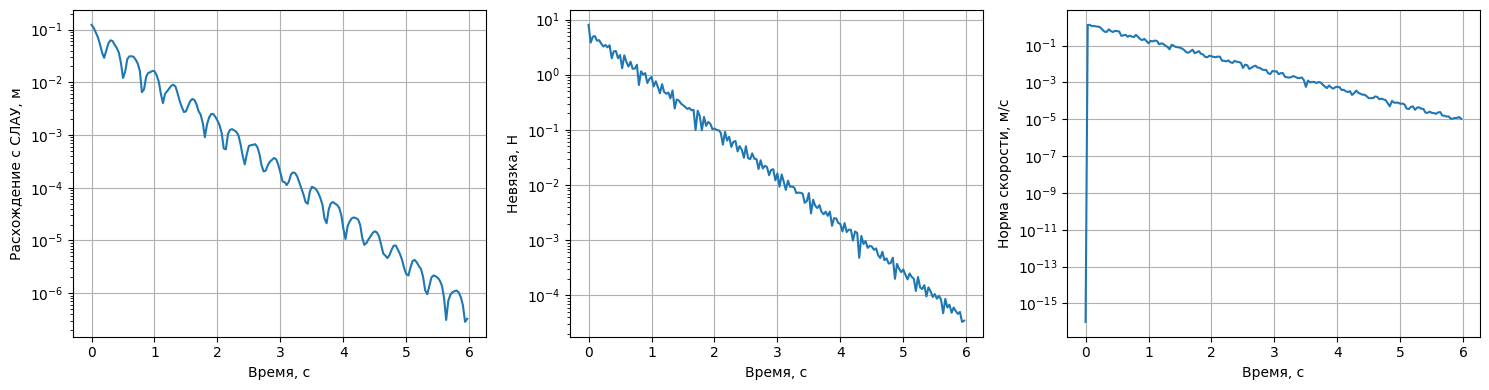

Относительное расхождение: 2.666879208972508e-06


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, values, label in zip(axes,
        [error_log, residual_log, velocity_log],
        ["Расхождение с СЛАУ, м", "Невязка, Н", "Норма скорости, м/с"]):
    ax.semilogy(time_log, np.maximum(values, 1e-16))
    ax.set(xlabel="Время, с", ylabel=label)
    ax.grid()
plt.tight_layout()
plt.show()
print("Относительное расхождение:",
      np.linalg.norm(grid_data.qpos-u_static)/np.linalg.norm(u_static))


### Количественное сравнение статики в MuJoCo с теорией


In [17]:
t = np.array(time_log)
err = np.array(error_log)

# 1. Сравним каждый узел с решением СЛАУ
u_sim = grid_data.qpos.copy()
print(f"Прогиб нагруженной площадки: СЛАУ = {u_static[loaded_node]*1000:.5f} мм, " f"MuJoCo = {u_sim[loaded_node]*1000:.5f} мм")
print(f"Максимальное отличие между узлами: {np.abs(u_sim - u_static).max()*1000:.2e} мм")

Прогиб нагруженной площадки: СЛАУ = 73.86644 мм, MuJoCo = 73.86652 мм
Максимальное отличие между узлами: 9.76e-05 мм


In [18]:
# 2. Главное уравнение: Mu'' + Cu' + Ku = f, где M = mI, C = cI.
# Проверим теорию о том, что в базисе собственных векторов K каждая мода удовлетворяет:
# ms^2 + cs + lambda = 0, а при c^2 < 4*m*lambda_min будут комплексные корни с Re(s) = -c/(2m)

lambda_min = np.linalg.eigvalsh(K)[0]
alpha = DAMPING / (2*MASS)
print(f"c^2 = {DAMPING**2:.3f}, 4*m*lambda_min = {4*MASS*lambda_min:.3f} -> " f"{'недодемпфированная' if DAMPING**2 < 4*MASS*lambda_min else 'передемпфированная'} система")
print(f"Теоретическая скорость затухания огибающей: {alpha:.3f} 1/с")

c^2 = 0.360, 4*m*lambda_min = 9.000 -> недодемпфированная система
Теоретическая скорость затухания огибающей: 2.000 1/с


In [19]:
# 3. Оценим скорость затухания по огибающей

win = 15
t_env = np.array([t[i:i+win].mean() for i in range(0, len(t) - win + 1, win)])
e_env = np.array([err[i:i+win].max() for i in range(0, len(t) - win + 1, win)])
slope = np.polyfit(t_env[1:], np.log(e_env[1:]), 1)[0]
print(f"Измеренная скорость затухания: {-slope:.5f} 1/с")



Измеренная скорость затухания: 1.98166 1/с


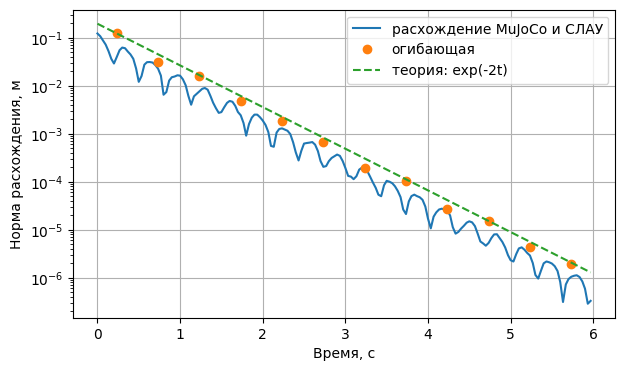

In [20]:
# Построим график эксперимента с огибающей

plt.figure(figsize=(7, 4))
plt.semilogy(t, np.maximum(err, 1e-16), label="расхождение MuJoCo и СЛАУ")
plt.semilogy(t_env, e_env, "o", label="огибающая")
plt.semilogy(t, e_env[0]*np.exp(-alpha*(t - t_env[0])), "--",
             label=f"теория: exp(-{alpha:.0f}t)")
plt.xlabel("Время, с")
plt.ylabel("Норма расхождения, м")
plt.grid()
plt.legend()
plt.show()

## А4. Численные эксперименты с СЛАУ
Для каждого эксперимента укажите параметры, представьте график или таблицу и объясните результат.

1. **Масштабируемость.** Решётки $5\times5$, $10\times10$, $20\times20$. Сравните время прямых методов и число итераций. Для больших задач видео строить необязательно.
2. **Несколько нагрузок.** Подготовьте не менее 10 правых частей при одной $K$. Отдельно измерьте время разложения и последующих решений для LU и Холецкого; сравните с повторным применением метода Гаусса.
3. **Начальный вектор.** Как начальные условия используйте нулевой, случайный единичной нормы и близкий к эталонному решению. Постройте ошибку и невязку по итерациям. Для графика ошибки добавьте сохранение приближений, не меняя основной интерфейс функции.
4. **Чувствительность.** Изменяйте $k_0$ при фиксированных размере и $k_c$. Сопоставьте число обусловленности $\nu(K)$, число итераций и изменение решения при малом возмущении $f$. Повторите для нескольких направлений возмущения.
5. **Свободная решётка.** Рассмотрите $k_0=0$. Объясните вырожденность и существование равновесия в зависимости от суммарной нагрузки. Не пытайтесь интерпретировать огромные числа от решателя как корректное единственное решение.

При изменении параметров заново собирайте матрицу и XML-модель. Для удобства можете вынести сборку решётки в функцию.


### Время экспериментов

In [21]:
# 1. Общие функуции проверок и согласований

def build_grid(side, k0, kc, load=8.0):
    """Матрица K, центральнай нагрузка f и геометрия решётки side*side"""
    m = side**2
    pts = np.array([[(c - (side - 1)/2)*SPACING, (r - (side - 1)/2)*SPACING]
                    for r in range(side) for c in range(side)])
    links = []
    for r in range(side):
        for c in range(side):
            i = r*side + c
            if c + 1 < side:
                links.append((i, i + 1))
            if r + 1 < side:
                links.append((i, i + side))
    Kg = k0*np.eye(m)
    for i, j in links:
        Kg[i, i] += kc
        Kg[j, j] += kc
        Kg[i, j] -= kc
        Kg[j, i] -= kc
    fg = np.zeros(m)
    fg[(side//2)*side + side//2] = load
    return Kg, fg, links, pts


def build_grid_model(side, k0, kc, mass=MASS, damping=DAMPING):
    """XML-модель MuJoCo для решётки side*side с любыми k0, kc"""
    _, _, links, pts = build_grid(side, k0, kc)
    bodies = "".join(f"""
    <body name="node_{i}" pos="{x} {y} {HEIGHT}">
      <joint name="joint_{i}" type="slide" axis="0 0 -1"
             stiffness="{k0}" springref="0" damping="{damping}"/>
      <geom type="box" size="{SPACING*0.42} {SPACING*0.42} 0.025" mass="{mass}"/>
    </body>""" for i, (x, y) in enumerate(pts))
    tendons = "".join(f"""
    <fixed name="spring_{i}_{j}" stiffness="{kc}" springlength="0">
      <joint joint="joint_{i}" coef="1"/>
      <joint joint="joint_{j}" coef="-1"/>
    </fixed>""" for i, j in links)
    xml = f"""
<mujoco>
  <option timestep="0.002" gravity="0 0 0" integrator="implicitfast"/>
  <default><geom contype="0" conaffinity="0"/></default>
  <worldbody>{bodies}</worldbody>
  <tendon>{tendons}</tendon>
</mujoco>"""
    return mujoco.MjModel.from_xml_string(xml)


def median_time(func, repeats=5):
    """Медиана времени по нескольким запускам и результат последнего"""
    times = []
    for _ in range(repeats):
        start = perf_counter()
        out = func()
        times.append(perf_counter() - start)
    return float(np.median(times)), out


def rel_err(u, u_ref):
    return np.linalg.norm(u - u_ref)/np.linalg.norm(u_ref)


def unit(v):
    return v/np.linalg.norm(v)

In [22]:
# Проверка
K_chk, f_chk, _, _ = build_grid(SIDE, K_SUPPORT, K_COUPLING)
np.testing.assert_allclose(K_chk, K)
np.testing.assert_allclose(f_chk, f)
probe_a4 = mujoco.MjData(build_grid_model(SIDE, K_SUPPORT, K_COUPLING))
probe_model = build_grid_model(SIDE, K_SUPPORT, K_COUPLING)
probe_a4.qpos[:] = np.random.default_rng(1).normal(0, 0.01, n)
mujoco.mj_forward(probe_model, probe_a4)
np.testing.assert_allclose(probe_a4.qfrc_passive, -K @ probe_a4.qpos, atol=1e-10)
print("build_grid и build_grid_model согласованы с матрицей K и моделью из А3")

build_grid и build_grid_model согласованы с матрицей K и моделью из А3


### Эксперимент №1

 решётка     n   cond |  Гаусс, мс    LU, мс  Холецкий, мс |  Якоби  Зейдель
  5×5       25   20.3 |       3.04      2.60          1.92 |    179       89
 10×10     100   21.8 |      37.50     27.13         13.61 |    193       97
 20×20     400   22.2 |     648.96    931.96        639.75 |    197      100


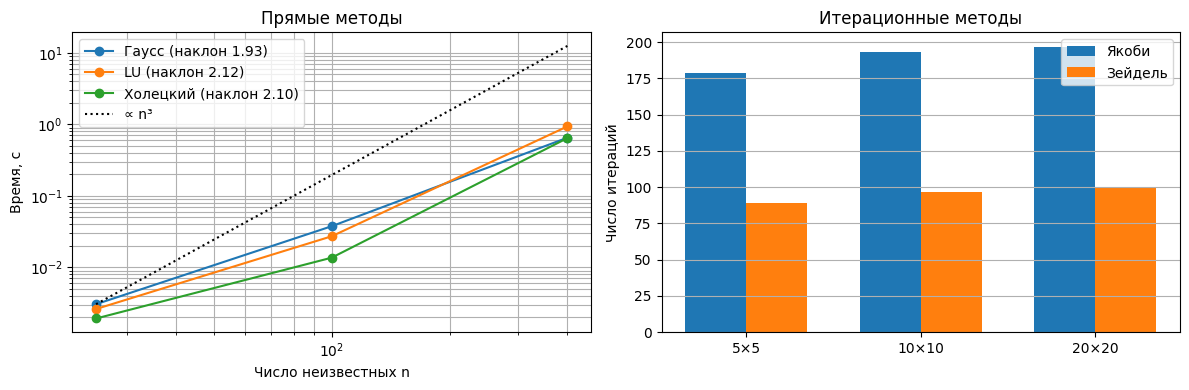

In [23]:
# Масштабируемость: решётки 5*5, 10*10, 20*20.

direct_solvers = [
    ("Гаусс", gauss),
    ("LU", lambda A, b: lu_solve(lu_factor(A), b)),
    ("Холецкий", cholesky_solve),
]

exp1 = []
for side in (5, 10, 20):
    K1, f1, _, _ = build_grid(side, K_SUPPORT, K_COUPLING)
    u_ref1 = np.linalg.solve(K1, f1) # эталон для проверки
    repeats = 5 if side < 20 else 3
    row = {"side": side, "n": side**2, "cond": np.linalg.cond(K1)}
    for name, solver in direct_solvers:
        row[name], u1 = median_time(lambda: solver(K1, f1), repeats)
        assert rel_err(u1, u_ref1) < 1e-10, name
    for method in ("jacobi", "seidel"):
        row[method + "_time"], (u1, r1) = median_time(
            lambda: iterative_solve(K1, f1, method), repeats)
        row[method + "_it"] = len(r1) - 1
        assert rel_err(u1, u_ref1) < 1e-6, method
    exp1.append(row)

print(f"{'решётка':>8} {'n':>5} {'cond':>6} | {'Гаусс, мс':>10} {'LU, мс':>9} "
      f"{'Холецкий, мс':>13} | {'Якоби':>6} {'Зейдель':>8}")
for r in exp1:
    print(f"{r['side']:>3}×{r['side']:<4} {r['n']:>5} {r['cond']:>6.1f} | "
          f"{r['Гаусс']*1e3:>10.2f} {r['LU']*1e3:>9.2f} {r['Холецкий']*1e3:>13.2f} | "
          f"{r['jacobi_it']:>6d} {r['seidel_it']:>8d}")

sizes = np.array([r["n"] for r in exp1])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, _ in direct_solvers:
    times = np.array([r[name] for r in exp1])
    slope = np.polyfit(np.log(sizes), np.log(times), 1)[0]
    axes[0].loglog(sizes, times, "o-", label=f"{name} (наклон {slope:.2f})")
axes[0].loglog(sizes, exp1[0]["Гаусс"]*(sizes/sizes[0])**3, "k:", label="∝ n³")
axes[0].set(xlabel="Число неизвестных n", ylabel="Время, с",
            title="Прямые методы")
axes[0].grid(which="both")
axes[0].legend()

width = 0.35
pos_x = np.arange(len(exp1))
axes[1].bar(pos_x - width/2, [r["jacobi_it"] for r in exp1], width, label="Якоби")
axes[1].bar(pos_x + width/2, [r["seidel_it"] for r in exp1], width, label="Зейдель")
axes[1].set_xticks(pos_x, [f"{r['side']}×{r['side']}" for r in exp1])
axes[1].set(ylabel="Число итераций", title="Итерационные методы")
axes[1].grid(axis="y")
axes[1].legend()
plt.tight_layout()
plt.show()

### Эксперимент №2

n = 400, правых частей: 20
Гаусс:    на одну правую часть   460.75 мс
LU:       разложение   324.51 мс, одно решение   3.85 мс
Холецкий: разложение   208.41 мс, одно решение   3.31 мс
Всего за 20 нагрузок, Гаусс                     :   9214.9 мс (ускорение   1.0x)
Всего за 20 нагрузок, LU                        :    401.6 мс (ускорение  22.9x)
Всего за 20 нагрузок, Холецкий                  :    274.6 мс (ускорение  33.6x)


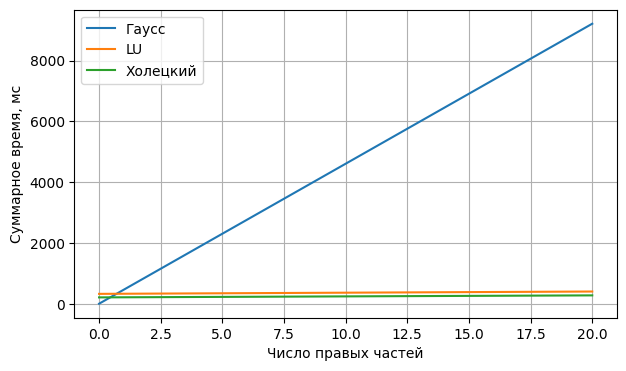

In [24]:
# Несколько нагрузок при одной матрице K

SIDE2, NRHS = 20, 20
K2, _, _, _ = build_grid(SIDE2, K_SUPPORT, K_COUPLING)
rng2 = np.random.default_rng(7)
F2 = rng2.normal(scale=5.0, size=(NRHS, SIDE2**2))   # 20 разных нагрузок
U2_ref = np.array([np.linalg.solve(K2, b) for b in F2])

def per_rhs_times(solve_one):
    """Время решения каждой правой части отдельно + сами решения."""
    times, sols = [], []
    for b in F2:
        t_one, x = median_time(lambda: solve_one(b), 3)
        times.append(t_one)
        sols.append(x)
    return np.array(times), np.array(sols)

# Гаусс
t_gauss, U_gauss = per_rhs_times(lambda b: gauss(K2, b))

# LU
t_lu_factor, lu_f = median_time(lambda: lu_factor(K2), 3)
t_lu_solve, U_lu = per_rhs_times(lambda b: lu_solve(lu_f, b))

# Холецкий
t_ch_factor, L2 = median_time(lambda: cholesky_factor(K2), 3)
t_ch_solve, U_ch = per_rhs_times(
    lambda b: backward_substitution(L2.T, forward_substitution(L2, b)))

for name, U in [("Гаусс", U_gauss), ("LU", U_lu), ("Холецкий", U_ch)]:
    assert max(rel_err(U[k], U2_ref[k]) for k in range(NRHS)) < 1e-10, name

total = {
    "Гаусс": t_gauss.sum(),
    "LU": t_lu_factor + t_lu_solve.sum(),
    "Холецкий": t_ch_factor + t_ch_solve.sum(),
}
print(f"n = {SIDE2**2}, правых частей: {NRHS}")
print(f"Гаусс:    на одну правую часть {t_gauss.mean()*1e3:8.2f} мс")
print(f"LU:       разложение {t_lu_factor*1e3:8.2f} мс, "
      f"одно решение {t_lu_solve.mean()*1e3:6.2f} мс")
print(f"Холецкий: разложение {t_ch_factor*1e3:8.2f} мс, "
      f"одно решение {t_ch_solve.mean()*1e3:6.2f} мс")
for name, value in total.items():
    print(f"Всего за {NRHS} нагрузок, {name:26s}: {value*1e3:8.1f} мс "
          f"(ускорение {total['Гаусс']/value:5.1f}x)")

k_axis = np.arange(0, NRHS + 1)
plt.figure(figsize=(7, 4))
plt.plot(k_axis, t_gauss.mean()*k_axis*1e3, label="Гаусс")
plt.plot(k_axis, (t_lu_factor + t_lu_solve.mean()*k_axis)*1e3, label="LU")
plt.plot(k_axis, (t_ch_factor + t_ch_solve.mean()*k_axis)*1e3, label="Холецкий")
plt.xlabel("Число правых частей")
plt.ylabel("Суммарное время, мс")
plt.grid()
plt.legend()
plt.show()


jacobi  нулевой                     : ошибка x_0 = 9.84e-02 м, невязка r_0 = 8.00e+00 Н, итераций = 193
jacobi  случайный, |x_0|=1          : ошибка x_0 = 1.01e+00 м, невязка r_0 = 1.92e+02 Н, итераций = 228
jacobi  около эталона (1% от |u|)   : ошибка x_0 = 9.84e-04 м, невязка r_0 = 1.70e-01 Н, итераций = 150
seidel  нулевой                     : ошибка x_0 = 9.84e-02 м, невязка r_0 = 8.00e+00 Н, итераций = 97
seidel  случайный, |x_0|=1          : ошибка x_0 = 1.01e+00 м, невязка r_0 = 1.92e+02 Н, итераций = 101
seidel  около эталона (1% от |u|)   : ошибка x_0 = 9.84e-04 м, невязка r_0 = 1.70e-01 Н, итераций = 66


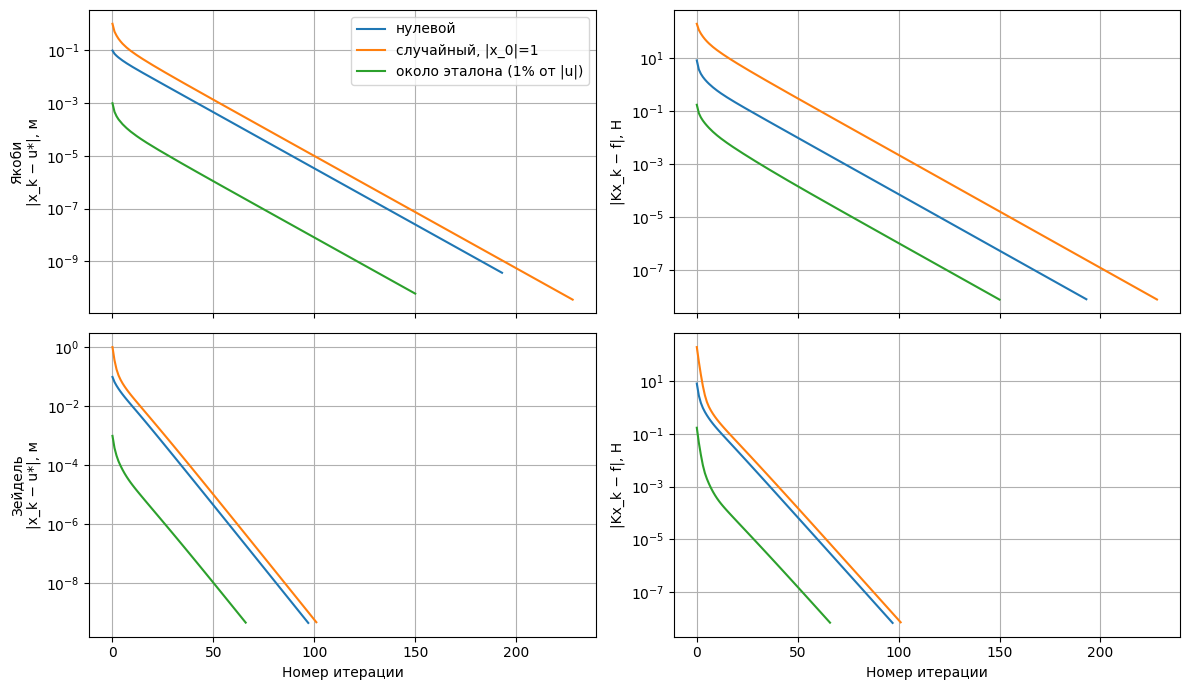

In [25]:
# Добавление начального вектора, решетку берем 10*10).
def iterative_history(A, b, method, x0, rtol=1e-9, atol=1e-12, max_iter=20000):
    x = np.array(x0, dtype=float)
    d = np.diag(A)
    threshold = atol + rtol*np.linalg.norm(b)
    residuals = [np.linalg.norm(A @ x - b)]
    iterates = [x.copy()]
    for _ in range(max_iter):
        if residuals[-1] <= threshold:
            return x, np.array(residuals), np.array(iterates)
        if method == "jacobi":
            x = (b - A @ x + d*x)/d
        else:
            for i in range(len(b)):
                x[i] = (b[i] - A[i, :i] @ x[:i] - A[i, i + 1:] @ x[i + 1:])/d[i]
        residuals.append(np.linalg.norm(A @ x - b))
        iterates.append(x.copy())
    raise RuntimeError("Не сошлось за max_iter итераций")


K3, f3, _, _ = build_grid(10, K_SUPPORT, K_COUPLING)
u_ref3 = np.linalg.solve(K3, f3)
rng3 = np.random.default_rng(3)

starts = {
    "нулевой": np.zeros(len(f3)),
    "случайный, |x_0|=1": unit(rng3.normal(size=len(f3))),
    "около эталона (1% от |u|)": u_ref3 + 0.01*np.linalg.norm(u_ref3)*unit(rng3.normal(size=len(f3))),
}

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex="col")
for row_ax, method in zip(axes, ("jacobi", "seidel")):
    for label, x0 in starts.items():
        x_end, res, its = iterative_history(K3, f3, method, x0)
        # Согласованность с основной функцией из А2.
        _, res_main = iterative_solve(K3, f3, method, x0=x0)
        assert len(res_main) == len(res)
        np.testing.assert_allclose(res_main, res, rtol=1e-6, atol=1e-12)
        errors = np.linalg.norm(its - u_ref3, axis=1)
        row_ax[0].semilogy(errors, label=label)
        row_ax[1].semilogy(res, label=label)
        print(f"{method:7s} {label:28s}: ошибка x_0 = {errors[0]:.2e} м, "
              f"невязка r_0 = {res[0]:.2e} Н, итераций = {len(res) - 1}")
    row_ax[0].set(ylabel=f"{'Якоби' if method == 'jacobi' else 'Зейдель'}\n|x_k − u*|, м")
    row_ax[1].set(ylabel="|Kx_k − f|, Н")
for ax in axes.ravel():
    ax.grid()
axes[0, 0].legend()
axes[1, 0].set_xlabel("Номер итерации")
axes[1, 1].set_xlabel("Номер итерации")
plt.tight_layout()
plt.show()


### Эксперимент №4

    k0     cond   Якоби  Зейдель |       случайное вдоль f (точка)      все вместе       шахматное   худший случай
   100      4.1      38       22 |            1.05            1.00            2.16            0.58            3.75
    15     21.8     193       97 |            1.18            1.00            5.42            0.30           18.21
     5     63.4     554      274 |            1.10            1.00            8.25            0.17           49.41
     1    313.2    2718     1336 |            0.51            1.00            9.86            0.04          224.69
   0.3   1041.6    9028     4435 |            0.31            1.00            9.99            0.01          729.39
   0.1   3122.7   27056    13290 |            0.27            1.00           10.00            0.00         2169.73
В последних столбцах: коэффициент усиления (‖δu‖/‖u‖)/(‖δf‖/‖f‖); верхняя оценка — cond(K).


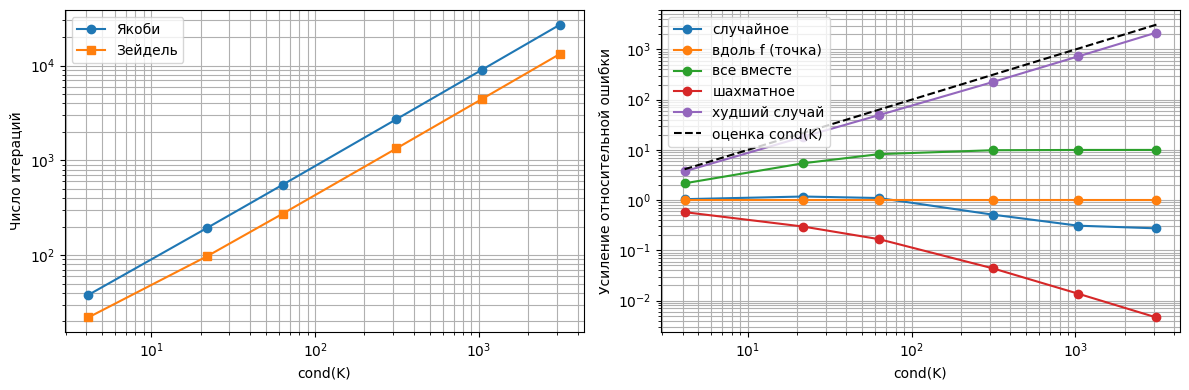

In [26]:
# Чувствительность: меняем k0 при фиксированных размере 10*10 и kc.
SIDE4, EPS = 10, 1e-3
rng4 = np.random.default_rng(11)
m4 = SIDE4**2
checker = np.array([(-1.0)**(r + c) for r in range(SIDE4) for c in range(SIDE4)])
directions = {
    "случайное": rng4.normal(size=m4),
    "вдоль f (точка)": build_grid(SIDE4, 1.0, 1.0)[1],
    "все вместе": np.ones(m4),
    "шахматное": checker,
}

WORST = "худший случай"

exp4 = []
for k0 in (100.0, 15.0, 5.0, 1.0, 0.3, 0.1):
    K4, f4, _, _ = build_grid(SIDE4, k0, K_COUPLING)
    u4 = gauss(K4, f4)
    row = {"k0": k0, "cond": np.linalg.cond(K4)}
    for method in ("jacobi", "seidel"):
        try:
            _, r4 = iterative_solve(K4, f4, method, max_iter=200_000)
            row[method] = len(r4) - 1
        except RuntimeError:
            row[method] = None
    for label, d_dir in directions.items():
        df = EPS*np.linalg.norm(f4)*unit(d_dir)
        du = gauss(K4, f4 + df) - u4
        row[label] = (np.linalg.norm(du)/np.linalg.norm(u4))/EPS
    f_w = checker
    u_w = gauss(K4, f_w)
    du_w = gauss(K4, f_w + EPS*np.linalg.norm(f_w)*unit(np.ones(m4))) - u_w
    row[WORST] = (np.linalg.norm(du_w)/np.linalg.norm(u_w))/EPS
    exp4.append(row)

names = list(directions) + [WORST]
print(f"{'k0':>6} {'cond':>8} {'Якоби':>7} {'Зейдель':>8} | "
      + " ".join(f"{nm[:15]:>15}" for nm in names))
for r in exp4:
    print(f"{r['k0']:>6g} {r['cond']:>8.1f} {str(r['jacobi']):>7} {str(r['seidel']):>8} | "
          + " ".join(f"{r[nm]:>15.2f}" for nm in names))
print("В последних столбцах: коэффициент усиления "
      "(‖δu‖/‖u‖)/(‖δf‖/‖f‖); верхняя оценка — cond(K).")

conds = np.array([r["cond"] for r in exp4])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].loglog(conds, [r["jacobi"] for r in exp4], "o-", label="Якоби")
axes[0].loglog(conds, [r["seidel"] for r in exp4], "s-", label="Зейдель")
axes[0].set(xlabel="cond(K)", ylabel="Число итераций")
axes[0].grid(which="both")
axes[0].legend()
for nm in names:
    axes[1].loglog(conds, [r[nm] for r in exp4], "o-", label=nm)
axes[1].loglog(conds, conds, "k--", label="оценка cond(K)")
axes[1].set(xlabel="cond(K)", ylabel="Усиление относительной ошибки")
axes[1].grid(which="both")
axes[1].legend()
plt.tight_layout()
plt.show()


‖K·1‖ = 0.0e+00  (вектор из единиц лежит в ядре K)
Два наименьших собственных значения: -2.85e-16, 15.28; cond(K) = 7.3e+16

Σf = 8.0 Н
Гаусс: ответ ‖u‖ = 1.88e+15 м, невязка = 3.60e+01 Н
Холецкий: ответ ‖u‖ = 4.02e+14 м, невязка = 8.31e+00 Н

      нагрузка   Σf, Н   ‖Ku − f‖, Н   min ‖Ku − f‖ (lstsq)
         центр    8.00      8.00e+00               1.60e+00
уравновешенная    0.00      6.91e-15               1.15e-14
|Σf|/√n = 1.60 Н — нижняя граница невязки при Σf ≠ 0
сдвиг всех площадок на +0.00 м: ‖K(u+c·1) − f‖ = 6.9e-15 Н
сдвиг всех площадок на +0.05 м: ‖K(u+c·1) − f‖ = 8.4e-15 Н
сдвиг всех площадок на -0.30 м: ‖K(u+c·1) − f‖ = 1.3e-14 Н

MuJoCo, Σf = 0: ‖K u − f‖ = 4.3e-07 Н, среднее смещение = -2.2e-17 м, отличие от решения минимальной нормы = 2.2e-08
MuJoCo, Σf = 8 Н: средняя скорость падения = 0.533 м/с; теория Σf/(n·c) = 0.533 м/с


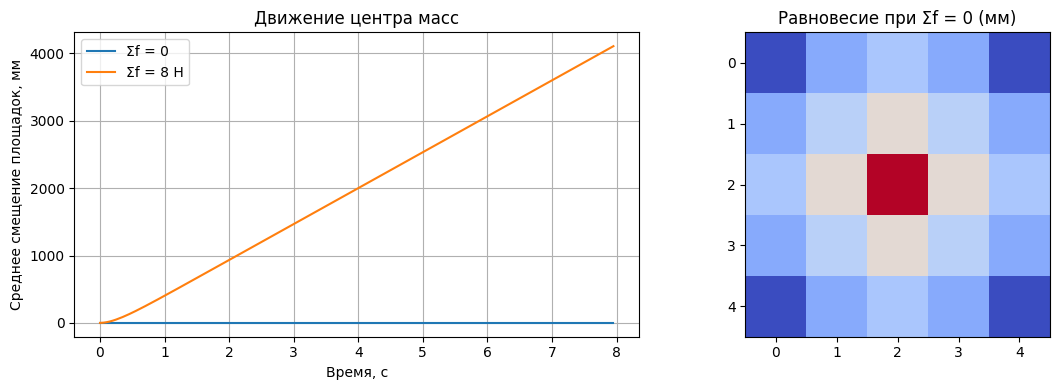

In [27]:
SIDE5 = 5
K5, f5, _, _ = build_grid(SIDE5, 0.0, K_COUPLING)
n5 = SIDE5**2
ones5 = np.ones(n5)
print(f"‖K·1‖ = {np.linalg.norm(K5 @ ones5):.1e}  (вектор из единиц лежит в ядре K)")
eig5 = np.linalg.eigvalsh(K5)
print(f"Два наименьших собственных значения: {eig5[0]:.2e}, {eig5[1]:.2f}; "
      f"cond(K) = {np.linalg.cond(K5):.1e}")

print(f"\nΣf = {f5.sum():.1f} Н")
for name, solver in [("Гаусс", gauss), ("Холецкий", cholesky_solve)]:
    try:
        u_bad = solver(K5, f5)
        print(f"{name}: ответ ‖u‖ = {np.linalg.norm(u_bad):.2e} м, "
              f"невязка = {np.linalg.norm(K5 @ u_bad - f5):.2e} Н")
    except Exception as exc:
        print(f"{name}: отказ — {type(exc).__name__}: {exc}")

def grounded_solution(Kfull, ffull):
    u = np.zeros(len(ffull))
    u[1:] = cholesky_solve(Kfull[1:, 1:], ffull[1:])
    return u

f5_balanced = f5.copy()
f5_balanced[[0, SIDE5 - 1, n5 - SIDE5, n5 - 1]] -= f5.sum()/4   # Σf = 0
print(f"\n{'нагрузка':>14} {'Σf, Н':>7} {'‖Ku − f‖, Н':>13} {'min ‖Ku − f‖ (lstsq)':>22}")
for label, load in [("центр", f5), ("уравновешенная", f5_balanced)]:
    u_g = grounded_solution(K5, load)
    u_ls = np.linalg.lstsq(K5, load, rcond=None)[0]       # эталон
    print(f"{label:>14} {load.sum():>7.2f} {np.linalg.norm(K5 @ u_g - load):>13.2e} "
          f"{np.linalg.norm(K5 @ u_ls - load):>22.2e}")
print(f"|Σf|/√n = {abs(f5.sum())/np.sqrt(n5):.2f} Н — нижняя граница невязки при Σf ≠ 0")

u_g = grounded_solution(K5, f5_balanced)
for shift in (0.0, 0.05, -0.3):
    print(f"сдвиг всех площадок на {shift:+.2f} м: "
          f"‖K(u+c·1) − f‖ = {np.linalg.norm(K5 @ (u_g + shift) - f5_balanced):.1e} Н")

free_model = build_grid_model(SIDE5, 0.0, K_COUPLING)
sim_t = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, load in [("Σf = 0", f5_balanced), ("Σf = 8 Н", f5)]:
    data = mujoco.MjData(free_model)
    ts, means = [], []
    for step in range(int(8.0/free_model.opt.timestep)):
        data.qfrc_applied[:] = load
        mujoco.mj_step(free_model, data)
        if step % 25 == 0:
            ts.append(data.time)
            means.append(data.qpos.mean())
    axes[0].plot(ts, np.array(means)*1000, label=label)
    sim_t[label] = (data.qpos.copy(), np.array(ts), np.array(means))

u_end = sim_t["Σf = 0"][0]
u_min_norm = np.linalg.lstsq(K5, f5_balanced, rcond=None)[0]
print(f"\nMuJoCo, Σf = 0: ‖K u − f‖ = {np.linalg.norm(K5 @ u_end - f5_balanced):.1e} Н, "
      f"среднее смещение = {u_end.mean():.1e} м, "
      f"отличие от решения минимальной нормы = {rel_err(u_end, u_min_norm):.1e}")
_, ts_, means_ = sim_t["Σf = 8 Н"]
late = ts_ > 4
speed = np.polyfit(ts_[late], means_[late], 1)[0]
print(f"MuJoCo, Σf = 8 Н: средняя скорость падения = {speed:.3f} м/с; "
      f"теория Σf/(n·c) = {f5.sum()/(n5*DAMPING):.3f} м/с")

axes[0].set(xlabel="Время, с", ylabel="Среднее смещение площадок, мм",
            title="Движение центра масс")
axes[0].grid()
axes[0].legend()
axes[1].imshow(u_end.reshape(SIDE5, SIDE5)*1000, cmap="coolwarm")
axes[1].set_title("Равновесие при Σf = 0 (мм)")
plt.tight_layout()
plt.show()


**Выводы А3–А4:** заполните здесь. Объясните увиденное, не только перечислите численные результаты.


## А5. Контрольные матрицы: обусловленность и расходимость
1. Для матриц Гильберта $H_{ij}=1/(i+j-1)$ размеров $5,7,9,12$ задайте $x_*=\mathbf1$, $b=Hx_*$. Сравните методы Гаусса, LU и Холецкого **на одной матрице $H$**. Вычислите ошибку, невязку и число обусловленности. Корректно зафиксируйте отказ разложения, если округления мешают его выполнению.
2. Отдельно рассмотрите $A=H^\top H$, $b=Ax^*$. Объясните, почему переход к этой матрице усиливает проблему обусловленности.
3. Для положительно определенной матрицы с преобладающей диагональю  $A=B^\top B+\alpha I$ (если $\alpha$ достаточно большое) при $n=100,300$ сравните прямые методы; при $n=500$ исследуйте методы Якоби и Зейделя.


In [28]:
import time
import numpy as np
from scipy.linalg import hilbert

for n in [5, 7, 9, 12]:
    H = hilbert(n)
    x_star = np.ones(n)
    b = H @ x_star
    print("Размер n =", n)
    print("Число обусловленности =", np.linalg.cond(H))
    try: # Гаусс
        x_gauss = gauss(H, b)
        print("Гаусс ошибка:", np.linalg.norm(x_gauss - x_star))
    except Exception as e:
        print("Гаусс отказ:", e)

    try: #LU
        P, L, U = lu_factor(H)
        x_lu = lu_solve((P, L, U), b)
        print("LU ошибка:", np.linalg.norm(x_lu - x_star))
    except Exception as e:
        print("LU отказ:", e)

    # Холецкий
    try:
        x_chol = cholesky_solve(H, b)
        print("Холецкий ошибка:", np.linalg.norm(x_chol - x_star))
    except Exception as e:
        print("Холецкий отказ:", e)

print()
print("2. Эксперимент с H^T H (n=7)")
H = hilbert(7)
A = H.T @ H
x_star = np.ones(7)
b = A @ x_star
print("Число обусловленности A =", np.linalg.cond(A))

try:
    x_chol2 = cholesky_solve(A, b)
    print("Холецкий ошибка:", np.linalg.norm(x_chol2 - x_star))
except Exception as e:
    print("Холецкий отказ:", e)
print()
print("3. Сравнение времени прямых методов")
for n in [100, 300]:
    np.random.seed(42)
    B = np.random.randn(n, n)
    A = B.T @ B + 1000 * np.eye(n)
    x_star = np.ones(n)
    b = A @ x_star
    print("Размер n =", n)

    t0 = time.perf_counter()
    gauss(A, b)
    print("Гаусс время:", time.perf_counter() - t0)

    t0 = time.perf_counter()
    P, L, U = lu_factor(A)
    lu_solve((P, L, U), b)
    print("LU время:", time.perf_counter() - t0)

    t0 = time.perf_counter()
    cholesky_solve(A, b)
    print("Холецкий время:", time.perf_counter() - t0)
print()
print("4. Итерационные методы (n=500)")
n = 500
np.random.seed(42)
B = np.random.randn(n, n)
A = B.T @ B + 5000 * np.eye(n)
x_star = np.ones(n)
b = A @ x_star

t0 = time.perf_counter()
x_jac, res_jac = iterative_solve(A, b, method="jacobi")
print("Якоби время:", time.perf_counter() - t0, "| Итераций:", len(res_jac)-1)

t0 = time.perf_counter()
x_seid, res_seid = iterative_solve(A, b, method="seidel")
print("Зейдель время:", time.perf_counter() - t0, "| Итераций:", len(res_seid)-1)

Размер n = 5
Число обусловленности = 476607.2502425855
Гаусс ошибка: 7.811402651223058e-13
LU ошибка: 8.289746575624257e-13
Холецкий ошибка: 6.350949804677493e-12
Размер n = 7
Число обусловленности = 475367356.7446793
Гаусс ошибка: 2.579755193036321e-08
LU ошибка: 3.4326063977681906e-08
Холецкий ошибка: 9.128789721577871e-09
Размер n = 9
Число обусловленности = 493153755941.02344
Гаусс ошибка: 9.412132079007291e-06
LU ошибка: 4.408101676355905e-05
Холецкий ошибка: 2.008767918263799e-05
Размер n = 12
Число обусловленности = 1.7515952300879806e+16
Гаусс отказ: Матрица вырождена
LU отказ: Матрица вырождена
Холецкий ошибка: 0.011011014849341756
2. Эксперимент с H^T H (n=7)
Число обусловленности A = 1.5915888467413264e+17
Холецкий ошибка: 4.128320574379871
3. Сравнение времени прямых методов
Размер n = 100
Гаусс время: 0.03650344600009703
LU время: 0.0313093879999542
Холецкий время: 0.02199251499996535
Размер n = 300
Гаусс время: 0.2593136620000678
LU время: 0.22814547600000878
Холецкий вре

**Выводы А5:** С ростом размера n число обусловленности растет экспоненциально, поэтому матрицы Гильберта - пример плохо обусловленных матриц. При n=12 накапливаются ошибки от округления, и метод Холецкого ломается (появляется отрицательное значение под корнем при извлечении диагонального элемента L), а метод Гаусса выдат очень боольшую ошибку.   Переход к $H^T H$: Обусловленность возводится в квадрат, система начитнает быть очень чуствительной, и даже для небольшой матрицы n=7 прямые методы завершаются с ошибкой.
Для хороших симметричных матриц большого размера (где диагональ усилена добавлением чисел) метод Холецкого работает быстрее всего. Итерационные методы на матрице 500x500 успешно сходятся, при этом метод Зейделя требует меньше шагов, чем Якоби, так как использует новые значения прямо в процессе текущей итерации


# Б. Обратная кинематика двухзвенного механизма
Решатели методом Гаусса или LU из части А теперь используется внутри нелинейного метода.


## 1. Модель механизма

Механизм состоит из двух звеньев длиной $l_1$ и $l_2$. Точка подвеса находится на высоте $z_0$. Движение происходит в вертикальной плоскости $xz$.

Обобщённые координаты:
- $q_1$ — угол первого звена относительно вертикали вниз;
- $q_2$ — угол второго звена относительно первого.

При $q_1=q_2=0$ оба звена направлены вертикально вниз.

В модели присутствуют гравитация, инерция и сопротивление в суставах. Два привода позволяют задавать моменты сил.


In [29]:
L1 = L2 = 0.7
BASE_Z = 1.7

arm_xml = f"""
<mujoco model="double_pendulum">
  <option timestep="0.002"
          gravity="0 0 -9.81"
          integrator="implicitfast"/>

  <visual>
    <global offwidth="640" offheight="480"/>
    <headlight ambient="0.5 0.5 0.5"/>
  </visual>

  <default>
    <joint damping="0.15" armature="0.01"/>
    <geom contype="0" conaffinity="0"/>
  </default>

  <worldbody>
    <light pos="0 -3 4" dir="0 1 -1"/>
    <camera name="front" pos="0 -4 1.1"
            xyaxes="1 0 0 0 0 1"/>

    <geom type="plane" size="3 3 0.1"
          rgba="0.92 0.94 0.97 1"/>

    <geom type="sphere" pos="0 0 {BASE_Z}"
          size="0.065" rgba="0.2 0.2 0.25 1"/>

    <body name="link1" pos="0 0 {BASE_Z}">
      <joint name="q1" type="hinge" axis="0 -1 0"/>
      <geom type="capsule"
            fromto="0 0 0 0 0 {-L1}"
            size="0.035" mass="1"
            rgba="0.15 0.45 0.9 1"/>

      <body name="link2" pos="0 0 {-L1}">
        <joint name="q2" type="hinge" axis="0 -1 0"/>
        <geom type="sphere" size="0.05"
              rgba="0.2 0.2 0.25 1"/>
        <geom type="capsule"
              fromto="0 0 0 0 0 {-L2}"
              size="0.03" mass="0.7"
              rgba="0.1 0.7 0.6 1"/>
        <site name="tip" pos="0 0 {-L2}"
              size="0.045" rgba="1 0.25 0.3 1"/>
      </body>
    </body>
  </worldbody>

  <actuator>
    <motor joint="q1" gear="1"/>
    <motor joint="q2" gear="1"/>
  </actuator>
</mujoco>
"""

arm_model = mujoco.MjModel.from_xml_string(arm_xml)
arm_data = mujoco.MjData(arm_model)
tip_id = mujoco.mj_name2id(
    arm_model, mujoco.mjtObj.mjOBJ_SITE, "tip"
)

print("Число степеней свободы:", arm_model.nv)


Число степеней свободы: 2


## 2. Прямая и обратная кинематика

Прямая кинематика определяет положение конца механизма по углам:

$$
p(q)=
\begin{pmatrix}
l_1\sin q_1+l_2\sin(q_1+q_2)\\
z_0-l_1\cos q_1-l_2\cos(q_1+q_2)
\end{pmatrix}.
$$

В обратной задаче известна целевая точка $p_*$, а углы требуется найти:

$$
F(q)=p(q)-p_*=0.
$$

Решение может быть не единственным. Кроме того, целевая точка может оказаться недостижимой.

Без ограничений на углы условие достижимости:

$$
|l_1-l_2|\leq \|p_*-(0,z_0)^\top\|_2\leq l_1+l_2.
$$

### Метод Ньютона

В окрестности текущего приближения $q_k$ используем линеаризацию:

$$
F(q_k+\Delta q_k)\approx F(q_k)+J(q_k)\Delta q_k,
$$

где $J$ — матрица Якоби. Приравнивая линейное приближение к нулю, получаем СЛАУ:

$$
J(q_k)\Delta q_k=-F(q_k).
$$

После её решения обновляем углы:

$$
q_{k+1}=q_k+\Delta q_k.
$$

Таким образом, каждая итерация Ньютона включает решение СЛАУ. Явно вычислять обратную матрицу не требуется.

Для двухзвенного механизма:

$$
J(q)=
\begin{pmatrix}
l_1\cos q_1+l_2\cos(q_1+q_2) & l_2\cos(q_1+q_2)\\
l_1\sin q_1+l_2\sin(q_1+q_2) & l_2\sin(q_1+q_2)
\end{pmatrix}.
$$


## Б1. Реализация кинематики и метода Ньютона
Реализуйте `endpoint`, аналитический `jacobian` и `inverse_kinematics`.

Реализуйте метод Ньютона, проверяйте невязку, ограничивайте число шагов, корректно обрабатывайте сингулярную систему и невозможность подобрать шаг.

Возвращайте `(q, iterations)`, где `iterations` — число сделанных обновлений. Для исследования сохраняйте историю невязки, поправки и шага в собственной диагностической функции. Не вычисляйте обратную матрицу явно.


In [30]:
class UnreachableTargetError(ValueError):
    """Цель недостижима для этих звеньев."""


def _check_array(target):
    target = np.asarray(target, dtype=float)
    if target.shape != (2,) or not np.all(np.isfinite(target)):
        raise ValueError("target должен быть вектором из двух конечных чисел")
    return target.copy()

def _check_reachability(target):
    radius = np.linalg.norm(target - np.array([0.0, BASE_Z]))
    lower, upper = abs(L1 - L2), L1 + L2
    tol = 1e-10 * max(1.0, upper)
    if radius < lower - tol or radius > upper + tol:
        raise UnreachableTargetError(
            "Цель недостижима: расстояние от подвеса {radius:.6g} м, "
            f"допустимый диапазон [{lower:.6g}, {upper:.6g}] м"
        )
    return None

def endpoint(q):
    # Б1: положение конца [x, z].
    q = _check_array(q)
    q1, q2 = q
    s = q1 + q2
    return np.array([
      L1 * np.sin(q1) + L2 * np.sin(s),
      BASE_Z - L1 * np.cos(q1) - L2 * np.cos(s)
    ])

def jacobian(q):
    # Б1: матрица частных производных 2×2.
    q = _check_array(q)
    q1, q2 = q
    s = q1 + q2
    return np.array([
      [L1 * np.cos(q1) + L2 * np.cos(s), L2 * np.cos(s)],
      [L1 * np.sin(q1) + L2 * np.sin(s), L2 * np.sin(s)],
    ])

def solve_linear(A, b):
    return gauss(A, b)

def inverse_kinematics_diagnostics(target, q0, tol=1e-9, max_iter=40,
                                  max_condition=1e12, max_backtracks=24):
    """Метод Ньютона с поиском шага; возвращает (q, updates, history, status).

    history хранит невязку, норму поправки, принятый шаг и cond(J).
    """
    target = _check_array(target)
    q = _check_array(q0)
    if tol <= 0 or max_iter < 0:
        raise ValueError("tol должен быть положительным, max_iter - неотрицательным")

    residual = endpoint(q) - target
    residual_norm = float(np.linalg.norm(residual))
    history = {
        "residual_norm": [residual_norm],
        "correction_norm": [],
        "step_size": [],
        "condition_number": [],
        "status": "running",
        "message": "",
    }
    try:
      _check_reachability(target)
      if residual_norm <= tol:
        history.update(status="converged", message="Начальное приближение уже удовлетворяет допуску")
        return q, 0, history, "converged"
    except UnreachableTargetError as e:
        history.update(status="unreachable", message=e)
        return q, 0, history, "unreachable"

    for _ in range(max_iter):
        J = jacobian(q)
        condition = float(np.linalg.cond(J))
        history["condition_number"].append(condition)
        if not np.isfinite(condition) or condition > max_condition:
            history["correction_norm"].append(np.nan)
            history["step_size"].append(0.0)
            message = f"Якобиан сингулярен или плохо обусловлен (cond(J)={condition:.3e})"
            history.update(status="singular_jacobian", message=message)
            return q, sum(a > 0 for a in history["step_size"]), history, "singular_jacobian"

        try:
            delta = solve_linear(J, -residual)
        except (ValueError, np.linalg.LinAlgError, FloatingPointError) as exc:
            history["correction_norm"].append(np.nan)
            history["step_size"].append(0.0)
            message = f"Не удалось решить линейный шаг Ньютона: {exc}"
            history.update(status="singular_jacobian", message=message)
            return q, sum(a > 0 for a in history["step_size"]), history, "singular_jacobian"

        delta_norm = float(np.linalg.norm(delta))
        history["correction_norm"].append(delta_norm)
        if not np.isfinite(delta_norm):
            history["step_size"].append(0.0)
            history.update(status="non_finite", message="Поправка Ньютона содержит NaN или Inf")
            return q, sum(a > 0 for a in history["step_size"]), history, "non_finite"

        alpha = 1.0
        accepted = False
        for _backtrack in range(max_backtracks + 1):
            q_trial = q + alpha * delta
            trial_residual = endpoint(q_trial) - target
            trial_norm = float(np.linalg.norm(trial_residual))
            if np.isfinite(trial_norm) and trial_norm <= (1.0 - 1e-4 * alpha) * residual_norm:
                accepted = True
                break
            alpha *= 0.5

        if not accepted:
            history["step_size"].append(0.0)
            history.update(status="line_search_failed",
                           message="Не удалось подобрать шаг, уменьшающий невязку")
            return q, sum(a > 0 for a in history["step_size"]), history, "line_search_failed"

        q = q_trial
        residual = trial_residual
        residual_norm = trial_norm
        history["step_size"].append(alpha)
        history["residual_norm"].append(residual_norm)
        if not np.isfinite(residual_norm):
            history.update(status="non_finite", message="Невязка стала нечисловой")
            return q, sum(a > 0 for a in history["step_size"]), history, "non_finite"
        if residual_norm <= tol:
            history.update(status="converged", message="Критерий невязки выполнен")
            return q, sum(a > 0 for a in history["step_size"]), history, "converged"

    history.update(status="max_iter", message=f"Нет сходимости за {max_iter} итераций")
    return q, sum(a > 0 for a in history["step_size"]), history, "max_iter"


def inverse_kinematics(target, q0, tol=1e-9, max_iter=40):
    # Б1: метод Ньютона.
    # Возвращает (q, iterations), не изменяет q0.
    q, iterations, history, status = inverse_kinematics_diagnostics(
        target, q0, tol=tol, max_iter=max_iter
    )
    if status == "unreachable":
        raise UnreachableTargetError(history["message"])
    if status != "converged":
        raise RuntimeError(f"Результат метода Ньютона не сошёлся ({status}): {history['message']}")
    return q, iterations


In [31]:
q_test = np.array([0.4, 1.2])
arm_data.qpos[:] = q_test
mujoco.mj_forward(arm_model, arm_data)
np.testing.assert_allclose(endpoint(q_test),
                          arm_data.site_xpos[tip_id][[0, 2]], atol=1e-10)
h = 1e-6
J_fd = np.column_stack([
    (endpoint(q_test+h*np.eye(2)[j])-endpoint(q_test-h*np.eye(2)[j]))/(2*h)
    for j in range(2)
])
np.testing.assert_allclose(jacobian(q_test), J_fd, atol=1e-7)
q_found, count = inverse_kinematics(endpoint(q_test), [0.3, 1.1])
assert np.linalg.norm(endpoint(q_found)-endpoint(q_test)) < 1e-8
print("Базовые проверки Б1 пройдены.")


Базовые проверки Б1 пройдены.


## 3. Расчёт заданных углов

Придумаем траекторию, чтобы манипулятор её исполнил. Сердечко задаётся параметрической кривой $p_*(t)$. Выбираем последовательность точек этой кривой и для каждой решаем обратную задачу кинематики.

Для первой точки задаём начальные углы вручную. Для следующих используем решение предыдущей задачи:

$$
q^{(0)}_{i+1}=q_i.
$$

При близких соседних точках это обычно сокращает число итераций и помогает сохранять одну ветвь решения.

На этом этапе мы рассчитываем **заданные углы**, а не физическое движение механизма.

Проверяем:
- достигнутую невязку;
- число итераций;
- непрерывность полученной последовательности углов.


Максимальная ошибка IK: 1.00e-09 м
Максимум итераций Ньютона: 4


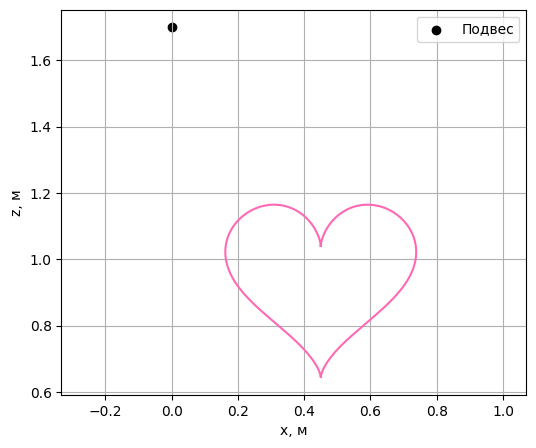

In [32]:
def heart(phase):
    """Сердечко целиком внутри рабочей области."""
    x = 16*np.sin(phase)**3
    z = (
        13*np.cos(phase)
        - 5*np.cos(2*phase)
        - 2*np.cos(3*phase)
        - np.cos(4*phase)
    )
    return np.array([
        0.45 + 0.018*x,
        0.95 + 0.018*z,
    ])

ARM_FPS = 30
ARM_DURATION = 12.0
N = int(ARM_FPS * ARM_DURATION)

times = np.arange(N + 1) / ARM_FPS
phases = 2*np.pi * times / ARM_DURATION
targets = np.array([heart(phase) for phase in phases])

q_reference = []
iteration_counts = []

q_guess = np.array([-0.4, 1.7])

for target in targets:
    q_guess, iterations = inverse_kinematics(target, q_guess)
    q_reference.append(q_guess.copy())
    iteration_counts.append(iterations)

q_reference = np.array(q_reference)
dq_reference = np.gradient(q_reference, 1/ARM_FPS, axis=0)

ik_errors = np.linalg.norm(
    np.array([endpoint(q) for q in q_reference]) - targets,
    axis=1,
)

print(f"Максимальная ошибка IK: {ik_errors.max():.2e} м")
print(f"Максимум итераций Ньютона: {max(iteration_counts)}")

plt.figure(figsize=(6, 5))
plt.plot(targets[:, 0], targets[:, 1], color="hotpink")
plt.scatter(0, BASE_Z, color="black", label="Подвес")
plt.axis("equal")
plt.xlabel("x, м")
plt.ylabel("z, м")
plt.legend()
plt.grid()
plt.show()


## 4. Физическое воспроизведение траектории

Рассчитанные углы становятся заданием для PD-регулятора:

$$
\tau=
K_P(q_{\mathrm{зад}}-q)
+
K_D(\dot q_{\mathrm{зад}}-\dot q)
+
b(q,\dot q),
$$

где $b(q,\dot q)$ компенсирует гравитационные и скоростные силы модели.

Регулятор задаёт моменты в суставах, а MuJoCo рассчитывает движение.

На видео:
- розовые точки — заданная траектория;
- красная точка — текущая цель;
- зелёный след — фактическое движение конца механизма.

Промежуточные итерации Ньютона на этом видео не показаны: обратная кинематика рассчитана заранее.


In [ ]:
def reference_at(t):
    """Линейная интерполяция заданных углов и скоростей."""
    t = np.clip(t, 0.0, ARM_DURATION)

    q = np.array([
        np.interp(t, times, q_reference[:, j])
        for j in range(2)
    ])

    dq = np.array([
        np.interp(t, times, dq_reference[:, j])
        for j in range(2)
    ])

    return q, dq


def add_dot(scene, point, radius, color):
    if scene.ngeom >= scene.maxgeom:
        return

    geom = scene.geoms[scene.ngeom]
    mujoco.mjv_initGeom(
        geom,
        mujoco.mjtGeom.mjGEOM_SPHERE,
        np.array([radius, radius, radius]),
        np.asarray(point, dtype=float),
        np.eye(3).ravel(),
        np.asarray(color, dtype=np.float32),
    )
    scene.ngeom += 1


mujoco.mj_resetData(arm_model, arm_data)
arm_data.qpos[:] = q_reference[0]
arm_data.qvel[:] = dq_reference[0]
mujoco.mj_forward(arm_model, arm_data)

KP = np.array([180.0, 100.0])
KD = np.array([25.0, 12.0])

arm_frames = []
actual_points = []

arm_renderer = mujoco.Renderer(
    arm_model, height=480, width=640, max_geom=3000
)

try:
    for frame_time in times[:-1]:
        while arm_data.time < frame_time - 1e-10:
            q_desired, dq_desired = reference_at(arm_data.time)

            # qfrc_bias компенсирует гравитацию и скоростные силы.
            arm_data.ctrl[:] = (
                KP * (q_desired - arm_data.qpos)
                + KD * (dq_desired - arm_data.qvel)
                + arm_data.qfrc_bias
            )
            mujoco.mj_step(arm_model, arm_data)

        # Обновляем положения site для текущего состояния.
        mujoco.mj_forward(arm_model, arm_data)
        actual_points.append(arm_data.site_xpos[tip_id].copy())

        arm_renderer.update_scene(arm_data, camera="front")
        scene = arm_renderer.scene

        # Заданная траектория: розовые точки.
        for x, z in targets[::3]:
            add_dot(
                scene, [x, -0.025, z], 0.005,
                [1.0, 0.45, 0.65, 1.0]
            )

        # След реального конца маятника.
        for point in actual_points:
            p = point.copy()
            p[1] = -0.045
            add_dot(
                scene, p, 0.007,
                [0.1, 0.75, 0.3, 1.0]
            )

        # Текущая цель.
        target = heart(2*np.pi * frame_time / ARM_DURATION)
        add_dot(
            scene, [target[0], -0.07, target[1]],
            0.025, [1.0, 0.15, 0.2, 1.0]
        )

        arm_frames.append(arm_renderer.render().copy())
finally:
    arm_renderer.close()

actual_points = np.array(actual_points)

media.show_video(arm_frames, fps=ARM_FPS)


## 5. Анализ ошибок

Различаем две ошибки.

**Ошибка обратной кинематики:**

$$
e_{\mathrm{IK}}(t)=
\|p(q_{\mathrm{зад}}(t))-p_*(t)\|_2.
$$

Она характеризует точность найденных углов относительно целевой точки.

**Ошибка физического слежения:**

$$
e_{\mathrm{track}}(t)=
\|p(q_{\mathrm{факт}}(t))-p_*(t)\|_2.
$$

Она зависит от динамики механизма, регулятора и скорости движения.

Даже при точном решении обратной кинематики фактическая траектория может отличаться от заданной.

### Сингулярные конфигурации

Для нашего якобиана

$$
\det J(q)=l_1l_2\sin q_2.
$$

Когда звенья лежат на одной прямой, якобиан вырождается. Вблизи таких конфигураций небольшое изменение цели может требовать большого изменения углов.

Исследуйте, как приближение к сингулярности влияет на поправку Ньютона, число итераций и чувствительность решения.


In [ ]:
actual_xz = actual_points[:, [0, 2]]
tracking_error = np.linalg.norm(
    actual_xz - targets[:-1], axis=1
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    targets[:, 0], targets[:, 1],
    "--", color="hotpink", label="Задание"
)
axes[0].plot(
    actual_xz[:, 0], actual_xz[:, 1],
    color="seagreen", label="MuJoCo"
)
axes[0].set_aspect("equal")
axes[0].set_xlabel("x, м")
axes[0].set_ylabel("z, м")
axes[0].legend()
axes[0].grid()

axes[1].plot(times[:-1], tracking_error * 1000)
axes[1].set_xlabel("Время, с")
axes[1].set_ylabel("Ошибка слежения, мм")
axes[1].grid()

plt.tight_layout()
plt.show()

print(f"Средняя ошибка: {tracking_error.mean()*1000:.2f} мм")
print(f"Максимальная ошибка: {tracking_error.max()*1000:.2f} мм")


## Б2–Б3. Исследование обратной кинематики
**Б2. Сходимость.** Для одной достижимой цели постройте карту по начальным углам $q_1,q_2\in[-\pi,\pi]$ (не менее $30\times30$ точек). Покажите число итераций, ветвь решения и неудачные старты. Углы сравнивайте с учётом периодичности $2\pi$.

Исследуйте недостижимую цель и цели около сингулярности. Постройте истории невязки, нормы поправки и числа обусловленности якобиана. Отличайте недостижимость от неудачи алгоритма при конкретном старте.

**Б3. Траектория.** Создайте собственную достижимую траекторию и воспроизведите её. Сравните минимум два времени обхода. Разделите ошибку IK в узлах траектории, погрешность интерполяции между узлами и ошибку физического слежения. Красная цель на видео должна соответствовать вашей новой траектории: замените `heart` в обоих местах или используйте единую функцию траектории.

Для исследования скорости сходимости используйте цель с невырожденным якобианом и достаточно близкий старт; квадратичная сходимость является локальным свойством.


In [ ]:
# Задание Б2
# Карта сходимости Ньютона для одной достижимой цели.
q_for_target = np.array([0.55, 1.0])
basin_target = endpoint(q_for_target)
grid_count = 35  # не меньше 30 x 30, как требуется в задании
angle_grid = np.linspace(-np.pi, np.pi, grid_count)
iteration_map = np.full((grid_count, grid_count), np.nan)
branch_map = np.full((grid_count, grid_count), np.nan)
failed_starts = []

for row, q2_start in enumerate(angle_grid):
    for col, q1_start in enumerate(angle_grid):
        q_start = np.array([q1_start, q2_start])
        q_sol, iters, hist, status = inverse_kinematics_diagnostics(
            basin_target, q_start, tol=1e-8, max_iter=60
        )
        if status == "converged":
            iteration_map[row, col] = iters
            # Знак sin(q2) не меняется при добавлении 2*pi и различает две ветви.
            s2 = np.sin(q_sol[1])
            branch_map[row, col] = 1 if s2 > 1e-8 else (-1 if s2 < -1e-8 else 0)
        else:
            failed_starts.append((q1_start, q2_start, status))

print(f"Б2: успешные старты {np.isfinite(iteration_map).sum()} / {grid_count**2}; "
      f"неудачные старты {len(failed_starts)}")
print("Ветвь sin(q2)>0:", int(np.nansum(branch_map == 1)),
      "; ветвь sin(q2)<0:", int(np.nansum(branch_map == -1)))
if failed_starts:
    q1_fail, q2_fail, status_fail = failed_starts[0]
    print(f"Пример отказа алгоритма при достижимой цели: q0=({q1_fail:.3f}, "
          f"{q2_fail:.3f}), статус={status_fail}. Это не означает, что цель недостижима.")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
im0 = axes[0].imshow(
    iteration_map, origin="lower", extent=[-np.pi, np.pi, -np.pi, np.pi],
    aspect="auto", interpolation="nearest"
)
axes[0].set_title("Число обновлений Ньютона")
axes[0].set_xlabel("Начальный $q_1$, рад")
axes[0].set_ylabel("Начальный $q_2$, рад")
fig.colorbar(im0, ax=axes[0], label="Итерации")

branch_cmap = plt.get_cmap("coolwarm").copy()
branch_cmap.set_bad("lightgray")
branch_masked = np.ma.masked_invalid(branch_map)
im1 = axes[1].imshow(
    branch_masked, origin="lower", extent=[-np.pi, np.pi, -np.pi, np.pi],
    aspect="auto", interpolation="nearest", cmap=branch_cmap, vmin=-1, vmax=1
)
axes[1].set_title("Ветвь решения (знак $\\sin q_2$)")
axes[1].set_xlabel("Начальный $q_1$, рад")
axes[1].set_ylabel("Начальный $q_2$, рад")
cb = fig.colorbar(im1, ax=axes[1], ticks=[-1, 0, 1])
cb.ax.set_yticklabels(["sin(q₂)<0", "около 0", "sin(q₂)>0"])

start_q1, start_q2 = np.meshgrid(angle_grid, angle_grid)
axes[2].scatter(start_q1.ravel(), start_q2.ravel(), s=8, color="0.8", label="Все старты")
if failed_starts:
    failed_arr = np.asarray([(x, y) for x, y, _ in failed_starts])
    axes[2].scatter(failed_arr[:, 0], failed_arr[:, 1], marker="x", s=18,
                    color="crimson", label="Неудачный старт")
axes[2].set_title("Неудачные начальные приближения")
axes[2].set_xlabel("Начальный $q_1$, рад")
axes[2].set_ylabel("Начальный $q_2$, рад")
axes[2].set_xlim(-np.pi, np.pi)
axes[2].set_ylim(-np.pi, np.pi)
axes[2].grid(alpha=0.25)
axes[2].legend(loc="best")
plt.tight_layout()
plt.show()

# Углы сравниваем с учётом периодичности 2*pi.
def angle_difference(a, b):
    return np.arctan2(np.sin(np.asarray(a) - np.asarray(b)),
                      np.cos(np.asarray(a) - np.asarray(b)))


# Истории невязки, поправки, принятого шага и cond(J) для обычной и почти
# сингулярной конфигураций.
q_regular = np.array([0.55, 0.9])
target_regular = endpoint(q_regular)
_, _, hist_regular, status_regular = inverse_kinematics_diagnostics(
    target_regular, q_regular + np.array([0.025, -0.02]), tol=1e-11, max_iter=40
)
q_near_singular = np.array([0.4, 0.01])
target_near_singular = endpoint(q_near_singular)
q_near_result, _, hist_near, status_near = inverse_kinematics_diagnostics(
    target_near_singular, q_near_singular + np.array([0.001, 0.001]),
    tol=1e-11, max_iter=60
)

unreachable_target = np.array([L1 + L2 + 0.05, BASE_Z])
_, _, hist_unreachable, status_unreachable = inverse_kinematics_diagnostics(
    unreachable_target, np.array([0.2, 0.5])
)
print("Регулярная цель:", status_regular,
      "; почти сингулярная цель:", status_near)
# Для регулярной цели достаточно близкого старта: оцениваем наблюдаемый порядок
# по p_k = log(e_(k+1)/e_k) / log(e_k/e_(k-1)). Значение около 2 согласуется
# с локальной квадратичной сходимостью Ньютона до достижения машинной точности.
r_regular = np.asarray(hist_regular["residual_norm"])
observed_orders = []
for k in range(1, len(r_regular) - 1):
    if min(r_regular[k-1:k+2]) > 0:
        denominator = np.log(r_regular[k] / r_regular[k-1])
        numerator = np.log(r_regular[k+1] / r_regular[k])
        if abs(denominator) > 1e-12:
            observed_orders.append(numerator / denominator)
print("Оценки локального порядка сходимости Ньютона:",
      np.round(observed_orders, 3) if observed_orders else "недостаточно шагов")
print("Цель за пределами рабочей области:", status_unreachable,
      "—", hist_unreachable["message"])
if status_near == "converged":
    perturbed_target = target_near_singular + np.array([-1e-6, 0.0])
    q_perturbed, _, hist_perturbed, status_perturbed = inverse_kinematics_diagnostics(
        perturbed_target, q_near_result, tol=1e-11, max_iter=60
    )
    if status_perturbed == "converged":
        dq_periodic = angle_difference(q_perturbed, q_near_result)
        print(f"Чувствительность около сингулярности: ||delta q||/||delta p|| = "
              f"{np.linalg.norm(dq_periodic)/1e-6:.3e} рад/м")
    else:
        print("Малое возмущение цели не сошлось:", hist_perturbed["message"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, hist, title in [
    (axes[0], hist_regular, "Регулярная конфигурация"),
    (axes[1], hist_near, "Вблизи сингулярности"),
]:
    ax.semilogy(np.arange(len(hist["residual_norm"])),
                np.maximum(hist["residual_norm"], 1e-16), "o-", label="Невязка")
    ax.set_title(title)
    ax.set_xlabel("Принятый шаг")
    ax.set_ylabel("Норма невязки, м")
    ax.grid(True, which="both", alpha=0.3)

axes[2].semilogy(np.maximum(hist_near["condition_number"], 1.0), "o-",
                 label="$cond(J)$, почти сингулярная")
axes[2].semilogy(np.maximum(hist_regular["condition_number"], 1.0), "s--",
                 label="$cond(J)$, регулярная")
axes[2].set_title("Обусловленность якобиана")
axes[2].set_xlabel("Номер линейного шага")
axes[2].set_ylabel("Число обусловленности")
axes[2].grid(True, which="both", alpha=0.3)
axes[2].legend()
plt.tight_layout()
plt.show()

# Дополнительные графики истории нормы поправки и выбранного шага.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for hist, label in [(hist_regular, "Регулярная"), (hist_near, "Почти сингулярная")]:
    axes[0].semilogy(np.maximum(hist["correction_norm"], 1e-16), "o-", label=label)
    axes[1].plot(hist["step_size"], "o-", label=label)
axes[0].set(title="Норма поправки Ньютона", xlabel="Итерация", ylabel="$||\\Delta q||_2$, рад")
axes[1].set(title="Принятая длина шага", xlabel="Итерация", ylabel="$\\alpha$")
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Задание Б3
# Сравниваем ту же пространственную кривую при двух временах обхода. Для
# каждого времени отдельно рассчитываем IK, ошибку линейной интерполяции и
# физическое слежение. Симуляция для сравнения выполняется без рендеринга.

def trajectory(phase):
    return np.array([
        0.38 + 0.13*np.cos(phase),
        0.96 + 0.10*np.sin(phase) + 0.025*np.sin(2*phase),
    ])

def make_reference(duration, fps=ARM_FPS, q_start=None):
    sample_times = np.arange(int(round(fps * duration)) + 1) / fps
    sample_phases = 2*np.pi * sample_times / duration
    sample_targets = np.array([trajectory(ph) for ph in sample_phases])
    q_values, counts = [], []
    q_guess = np.array([0.3, 1.7]) if q_start is None else np.array(q_start, dtype=float).copy()
    for point in sample_targets:
        q_guess, count = inverse_kinematics(point, q_guess, tol=1e-10, max_iter=50)
        q_values.append(q_guess.copy())
        counts.append(count)
    q_values = np.asarray(q_values)
    qd_values = np.gradient(q_values, 1/fps, axis=0)
    node_error = np.linalg.norm(
        np.array([endpoint(q) for q in q_values]) - sample_targets, axis=1
    )
    mid_times = 0.5 * (sample_times[:-1] + sample_times[1:])
    mid_phases = 2*np.pi * mid_times / duration
    mid_targets = np.array([trajectory(ph) for ph in mid_phases])
    q_mid = 0.5 * (q_values[:-1] + q_values[1:])
    interp_error = np.linalg.norm(
        np.array([endpoint(q) for q in q_mid]) - mid_targets, axis=1
    )
    return sample_times, sample_targets, q_values, qd_values, node_error, mid_times, interp_error, counts


def simulate_tracking(sample_times, sample_targets, q_values, qd_values):
    data = mujoco.MjData(arm_model)
    data.qpos[:] = q_values[0]
    data.qvel[:] = qd_values[0]
    mujoco.mj_forward(arm_model, data)
    actual_xz = []
    dt = float(arm_model.opt.timestep)
    for frame_time in sample_times[:-1]:
        while data.time < frame_time - 1e-10:
            q_desired = np.array([
                np.interp(data.time, sample_times, q_values[:, j]) for j in range(2)
            ])
            dq_desired = np.array([
                np.interp(data.time, sample_times, qd_values[:, j]) for j in range(2)
            ])
            data.ctrl[:] = (
                KP * (q_desired - data.qpos)
                + KD * (dq_desired - data.qvel)
                + data.qfrc_bias
            )
            mujoco.mj_step(arm_model, data)
        mujoco.mj_forward(arm_model, data)
        actual_xz.append(data.site_xpos[tip_id][[0, 2]].copy())
    actual_xz = np.asarray(actual_xz)
    return np.linalg.norm(actual_xz - sample_targets[:-1], axis=1)


duration_results = []
for duration in (ARM_DURATION, ARM_DURATION / 2):
    (t_run, p_run, q_run, dq_run, node_err, t_mid,
     interp_err, run_counts) = make_reference(duration)
    track_err = simulate_tracking(t_run, p_run, q_run, dq_run)
    duration_results.append({
        "duration": duration, "times": t_run, "targets": p_run,
        "q": q_run, "node_error": node_err, "mid_times": t_mid,
        "interp_error": interp_err, "tracking_error": track_err,
        "counts": run_counts,
    })

print("Б3: сравнение времени обхода")
print(f"{'T, c':>8} {'max IK, мм':>14} {'max interp., мм':>17} "
      f"{'mean track, мм':>17} {'max track, мм':>16} {'max iter.':>11}")
for result in duration_results:
    print(f"{result['duration']:8.2f} "
          f"{result['node_error'].max()*1000:14.6f} "
          f"{result['interp_error'].max()*1000:17.6f} "
          f"{result['tracking_error'].mean()*1000:17.4f} "
          f"{result['tracking_error'].max()*1000:16.4f} "
          f"{max(result['counts']):11d}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for result in duration_results:
    duration = result["duration"]
    phase_node = result["times"] / duration
    phase_mid = result["mid_times"] / duration
    axes[0].semilogy(phase_node, np.maximum(result["node_error"]*1000, 1e-12),
                     label=f"T={duration:g} c")
    axes[1].plot(phase_mid, result["interp_error"]*1000,
                 label=f"T={duration:g} c")
    axes[2].plot(phase_node[:-1], result["tracking_error"]*1000,
                 label=f"T={duration:g} c")
axes[0].set(title="Ошибка IK в узлах", xlabel="Доля периода", ylabel="Ошибка, мм")
axes[1].set(title="Ошибка между узлами", xlabel="Доля периода", ylabel="Ошибка, мм")
axes[2].set(title="Ошибка физического слежения", xlabel="Доля периода", ylabel="Ошибка, мм")
for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Визуализация траектории для Б3

times = np.arange(N + 1) / ARM_FPS
phases = 2*np.pi * times / ARM_DURATION
targets = np.array([trajectory(phase) for phase in phases])

q_reference = []
iteration_counts = []

q_guess = np.array([-0.4, 1.7])

for target in targets:
    q_guess, iterations = inverse_kinematics(target, q_guess)
    q_reference.append(q_guess.copy())
    iteration_counts.append(iterations)

q_reference = np.array(q_reference)
dq_reference = np.gradient(q_reference, 1/ARM_FPS, axis=0)

plt.figure(figsize=(6, 5))
plt.plot(targets[:, 0], targets[:, 1], color="hotpink")
plt.scatter(0, BASE_Z, color="black", label="Подвес")
plt.axis("equal")
plt.xlabel("x, м")
plt.ylabel("z, м")
plt.legend()
plt.grid()
plt.show()


mujoco.mj_resetData(arm_model, arm_data)
arm_data.qpos[:] = q_reference[0]
arm_data.qvel[:] = dq_reference[0]
mujoco.mj_forward(arm_model, arm_data)

arm_frames = []
actual_points = []

arm_renderer = mujoco.Renderer(
    arm_model, height=480, width=640, max_geom=3000
)

try:
    for frame_time in times[:-1]:
        while arm_data.time < frame_time - 1e-10:
            q_desired, dq_desired = reference_at(arm_data.time)

            # qfrc_bias компенсирует гравитацию и скоростные силы.
            arm_data.ctrl[:] = (
                KP * (q_desired - arm_data.qpos)
                + KD * (dq_desired - arm_data.qvel)
                + arm_data.qfrc_bias
            )
            mujoco.mj_step(arm_model, arm_data)

        # Обновляем положения site для текущего состояния.
        mujoco.mj_forward(arm_model, arm_data)
        actual_points.append(arm_data.site_xpos[tip_id].copy())

        arm_renderer.update_scene(arm_data, camera="front")
        scene = arm_renderer.scene

        # Заданная траектория: розовые точки.
        for x, z in targets[::3]:
            add_dot(
                scene, [x, -0.025, z], 0.005,
                [1.0, 0.45, 0.65, 1.0]
            )

        # След реального конца маятника.
        for point in actual_points:
            p = point.copy()
            p[1] = -0.045
            add_dot(
                scene, p, 0.007,
                [0.1, 0.75, 0.3, 1.0]
            )

        # Текущая цель.
        target = trajectory(2*np.pi * frame_time / ARM_DURATION)
        add_dot(
            scene, [target[0], -0.07, target[1]],
            0.025, [1.0, 0.15, 0.2, 1.0]
        )

        arm_frames.append(arm_renderer.render().copy())
finally:
    arm_renderer.close()

actual_points = np.array(actual_points)

media.show_video(arm_frames, fps=ARM_FPS)

**Выводы Б:**
1. Прямая кинематика вычисляет положение конца манипулятора аналитически, а метод Ньютона использует якобиан и решает линейную систему на каждом шаге.
2. Карта сходимости показывает зависимость количества шагов и найденной ветви от начальных углов. Две ветви соответствуют разным знакам $\sin q_2$; при сравнении углов необходимо учитывать периодичность $2\pi$. Вблизи вырожденного якобиана число обусловленности растёт, поэтому поправка Ньютона и найденные углы становятся чувствительнее к возмущениям.
3. При сравнении двух времён обхода ошибка IK в узлах характеризует точность нелинейного решения, ошибка между узлами — приближение траектории линейной интерполяцией углов, а ошибка физического слежения дополнительно зависит от динамики MuJoCo и настроек PD-регулятора. Обычно более быстрое движение увеличивает динамическую ошибку слежения.



# В. Сдача
Сдайте заполненный `.ipynb` с реализациями, воспроизводимыми экспериментами, графиками и выводами. Видео можно не сохранять внутри файла: оставьте код их получения. Случайные генераторы должны иметь фиксированный seed.

Перед сдачей перезапустите сеанс и выполните ячейки последовательно. Уберите отладочный вывод и убедитесь, что обязательные TODO заполнены. Ожидаемые отказы в экспериментах перехватывайте и подписывайте; они не должны обрывать весь блокнот.
